In [1]:
import os

DATASET_PATH = "/kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset path:", DATASET_PATH)

if os.path.exists(DATASET_PATH):
    print("\nItems:")
    for item in sorted(os.listdir(DATASET_PATH)):
        print(item)

Dataset exists: True
Dataset path: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset

Items:
COVID
COVID.metadata.xlsx
Lung_Opacity
Lung_Opacity.metadata.xlsx
Normal
Normal.metadata.xlsx
README.md.txt
Viral Pneumonia
Viral Pneumonia.metadata.xlsx


In [2]:
import os

CLASS_MAP = {
    "COVID": "COVID",
    "Normal": "Normal",
    "Viral Pneumonia": "Viral Pneumonia",
    "Lung Opacity": "Lung_Opacity"
}

for class_name, folder_name in CLASS_MAP.items():
    class_path = os.path.join(DATASET_PATH, folder_name)
    image_path = os.path.join(class_path, "images")
    mask_path = os.path.join(class_path, "masks")

    images = [
        f for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    masks = [
        f for f in os.listdir(mask_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"\n{class_name}")
    print("Folder:", class_path)
    print("Images:", len(images))
    print("Masks:", len(masks))
    print("Images folder exists:", os.path.isdir(image_path))
    print("Masks folder exists:", os.path.isdir(mask_path))


COVID
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID
Images: 3616
Masks: 3616
Images folder exists: True
Masks folder exists: True

Normal
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal
Images: 10192
Masks: 10192
Images folder exists: True
Masks folder exists: True

Viral Pneumonia
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia
Images: 1345
Masks: 1345
Images folder exists: True
Masks folder exists: True

Lung Opacity
Folder: /kaggle/input/datasets/tawsifurrahman/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity
Images: 6012
Masks: 6012
Images folder exists: True
Masks folder exists: True


In [3]:
import os

for class_name, folder_name in CLASS_MAP.items():
    image_path = os.path.join(DATASET_PATH, folder_name, "images")
    mask_path = os.path.join(DATASET_PATH, folder_name, "masks")

    image_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    mask_files = {
        os.path.splitext(f)[0]
        for f in os.listdir(mask_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    matched = image_files & mask_files
    missing_masks = image_files - mask_files
    missing_images = mask_files - image_files

    print(f"\n{class_name}")
    print("Images:", len(image_files))
    print("Masks:", len(mask_files))
    print("Matched:", len(matched))
    print("Missing masks:", len(missing_masks))
    print("Missing images:", len(missing_images))

    if missing_masks:
        print("Example missing masks:", list(missing_masks)[:5])

    if missing_images:
        print("Example missing images:", list(missing_images)[:5])


COVID
Images: 3616
Masks: 3616
Matched: 3616
Missing masks: 0
Missing images: 0

Normal
Images: 10192
Masks: 10192
Matched: 10192
Missing masks: 0
Missing images: 0

Viral Pneumonia
Images: 1345
Masks: 1345
Matched: 1345
Missing masks: 0
Missing images: 0

Lung Opacity
Images: 6012
Masks: 6012
Matched: 6012
Missing masks: 0
Missing images: 0


In [4]:
import os
import random
import pandas as pd

SEED = 42
SAMPLES_PER_CLASS = 1345

random.seed(SEED)

records = []

for label, (class_name, folder_name) in enumerate(CLASS_MAP.items()):
    image_path = os.path.join(DATASET_PATH, folder_name, "images")
    mask_path = os.path.join(DATASET_PATH, folder_name, "masks")

    image_files = sorted([
        f for f in os.listdir(image_path)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    selected_files = random.sample(image_files, SAMPLES_PER_CLASS)

    for filename in selected_files:
        records.append({
            "image_path": os.path.join(image_path, filename),
            "mask_path": os.path.join(mask_path, filename),
            "class_name": class_name,
            "label": label
        })

df = pd.DataFrame(records)

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

csv_path = "/kaggle/working/balanced_5380_dataset.csv"
df.to_csv(csv_path, index=False)

print("Total samples:", len(df))
print("\nClass distribution:")
print(df["class_name"].value_counts().sort_index())

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\nCSV saved to:", csv_path)

print("\nFirst 5 records:")
print(df.head())

Total samples: 5380

Class distribution:
class_name
COVID              1345
Lung Opacity       1345
Normal             1345
Viral Pneumonia    1345
Name: count, dtype: int64

Label distribution:
label
0    1345
1    1345
2    1345
3    1345
Name: count, dtype: int64

CSV saved to: /kaggle/working/balanced_5380_dataset.csv

First 5 records:
                                          image_path  \
0  /kaggle/input/datasets/tawsifurrahman/covid19-...   
1  /kaggle/input/datasets/tawsifurrahman/covid19-...   
2  /kaggle/input/datasets/tawsifurrahman/covid19-...   
3  /kaggle/input/datasets/tawsifurrahman/covid19-...   
4  /kaggle/input/datasets/tawsifurrahman/covid19-...   

                                           mask_path    class_name  label  
0  /kaggle/input/datasets/tawsifurrahman/covid19-...         COVID      0  
1  /kaggle/input/datasets/tawsifurrahman/covid19-...  Lung Opacity      3  
2  /kaggle/input/datasets/tawsifurrahman/covid19-...         COVID      0  
3  /kaggle/input/

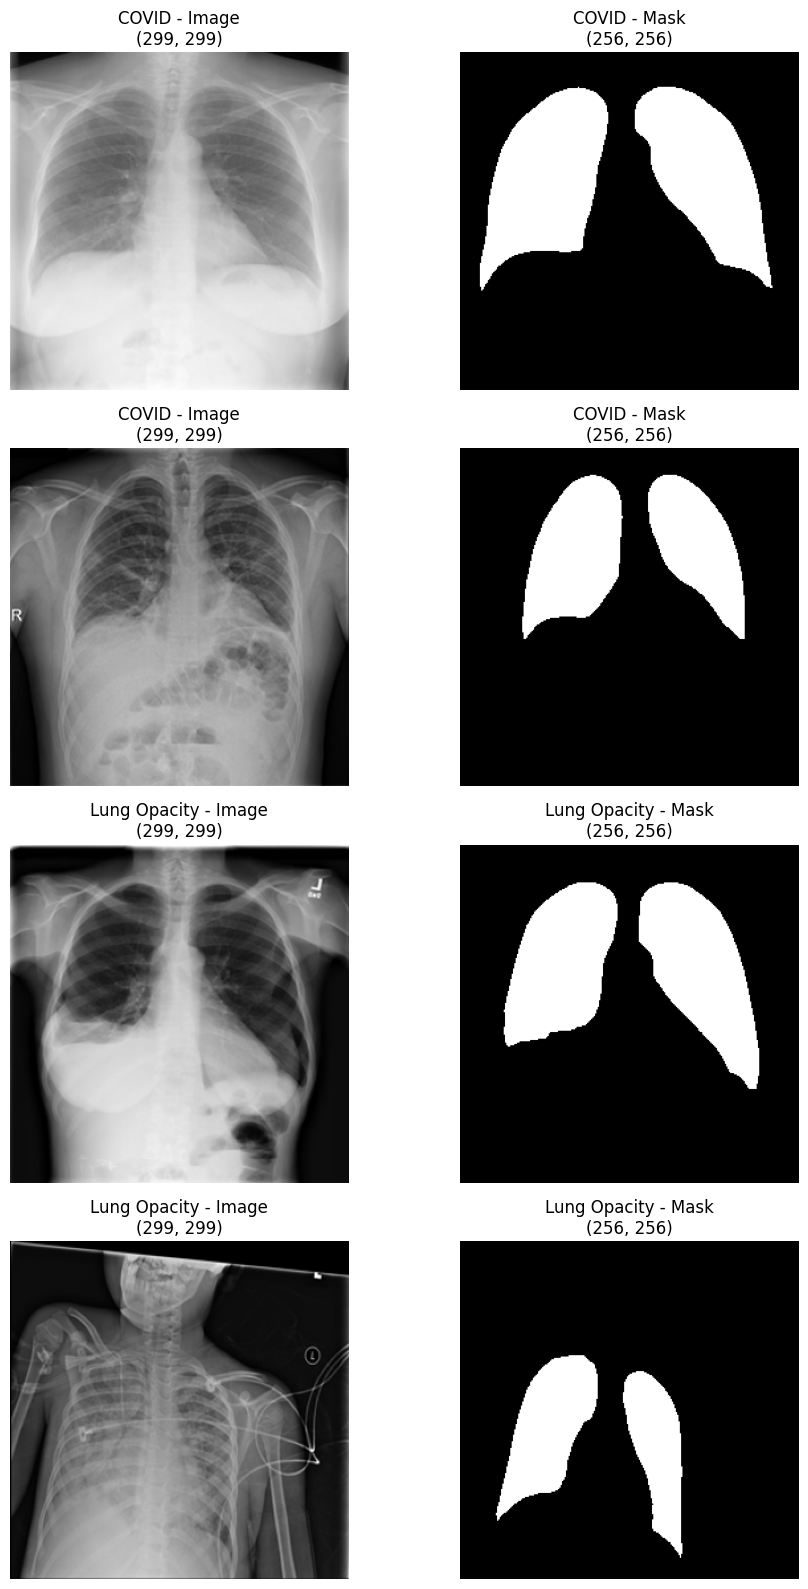

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

sample_indices = [0, 1345, 2690, 4035]

fig, axes = plt.subplots(4, 2, figsize=(10, 16))

for row, idx in enumerate(sample_indices):
    image = Image.open(df.iloc[idx]["image_path"]).convert("L")
    mask = Image.open(df.iloc[idx]["mask_path"]).convert("L")

    axes[row, 0].imshow(image, cmap="gray")
    axes[row, 0].set_title(
        f'{df.iloc[idx]["class_name"]} - Image\n{image.size}'
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title(
        f'{df.iloc[idx]["class_name"]} - Mask\n{mask.size}'
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [6]:
import numpy as np
from PIL import Image

coverage_results = []

for idx in sample_indices:
    image = np.array(Image.open(df.iloc[idx]["image_path"]).convert("L"))
    mask = np.array(Image.open(df.iloc[idx]["mask_path"]).convert("L"))

    mask_binary = mask > 0
    coverage = mask_binary.mean() * 100

    coverage_results.append({
        "class": df.iloc[idx]["class_name"],
        "image_shape": image.shape,
        "mask_shape": mask.shape,
        "mask_min": mask.min(),
        "mask_max": mask.max(),
        "mask_mean": mask.mean(),
        "lung_coverage_percent": coverage
    })

coverage_df = pd.DataFrame(coverage_results)

print(coverage_df.to_string(index=False))

print("\nOverall mask statistics:")
print("Minimum mask value:", coverage_df["mask_min"].min())
print("Maximum mask value:", coverage_df["mask_max"].max())
print("Minimum lung coverage:", coverage_df["lung_coverage_percent"].min())
print("Maximum lung coverage:", coverage_df["lung_coverage_percent"].max())

       class image_shape mask_shape  mask_min  mask_max  mask_mean  lung_coverage_percent
       COVID  (299, 299) (256, 256)         0       255  67.539825              26.486206
       COVID  (299, 299) (256, 256)         0       255  43.882599              17.208862
Lung Opacity  (299, 299) (256, 256)         0       255  58.773422              23.048401
Lung Opacity  (299, 299) (256, 256)         0       255  34.481964              13.522339

Overall mask statistics:
Minimum mask value: 0
Maximum mask value: 255
Minimum lung coverage: 13.5223388671875
Maximum lung coverage: 26.4862060546875


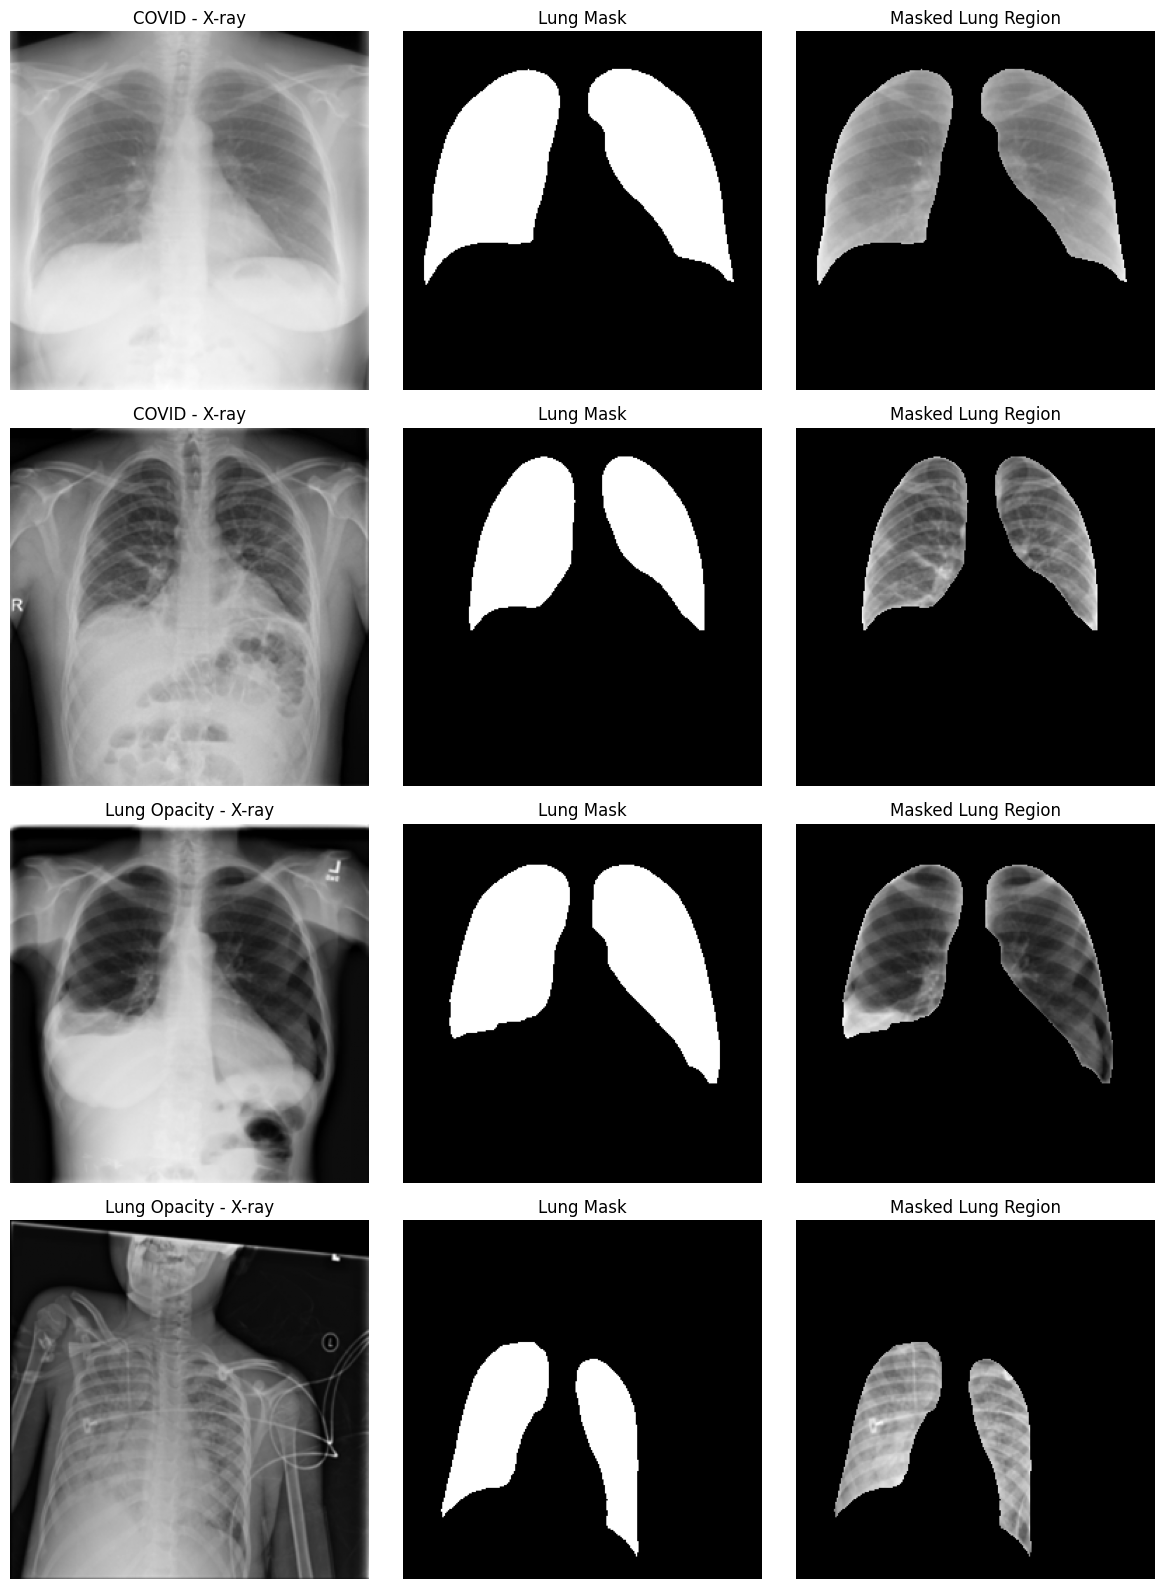

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_indices = [0, 1345, 2690, 4035]

fig, axes = plt.subplots(4, 3, figsize=(12, 16))

for row, idx in enumerate(sample_indices):
    image = Image.open(df.iloc[idx]["image_path"]).convert("L")
    mask = Image.open(df.iloc[idx]["mask_path"]).convert("L")

    image_resized = image.resize((256, 256), Image.Resampling.BILINEAR)
    mask_array = np.array(mask)
    image_array = np.array(image_resized)

    masked_image = image_array.copy()
    masked_image[mask_array == 0] = 0

    axes[row, 0].imshow(image_array, cmap="gray")
    axes[row, 0].set_title(f'{df.iloc[idx]["class_name"]} - X-ray')
    axes[row, 0].axis("off")

    axes[row, 1].imshow(mask_array, cmap="gray")
    axes[row, 1].set_title("Lung Mask")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(masked_image, cmap="gray")
    axes[row, 2].set_title("Masked Lung Region")
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

In [8]:
from sklearn.model_selection import train_test_split

full_df = df.copy()

development_df, test_df = train_test_split(
    full_df,
    test_size=0.15,
    stratify=full_df["label"],
    random_state=42
)

heldout_test_paths = set(test_df["image_path"])

df = development_df.reset_index(drop=True)   # k-fold CV uses ONLY this

assert heldout_test_paths.isdisjoint(set(df["image_path"])), "Leak: test images found in the CV data!"

print(f"Full dataset            : {len(full_df)}")
print(f"Development set (k-fold): {len(df)}")
print(f"Held-out test set       : {len(test_df)}  (never used for k-fold, U-Net-for-CV, or model selection)")

Full dataset            : 5380
Development set (k-fold): 4573
Held-out test set       : 807  (never used for k-fold, U-Net-for-CV, or model selection)


In [9]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

df["fold"] = -1

for fold, (_, val_idx) in enumerate(
    skf.split(df, df["label"])
):
    df.loc[val_idx, "fold"] = fold

print("Fold distribution:")
print(
    df.groupby(["fold", "class_name"])
      .size()
      .unstack(fill_value=0)
)

print("\nSamples per fold:")
print(df["fold"].value_counts().sort_index())

print("\nTotal samples:", len(df))

Fold distribution:
class_name  COVID  Lung Opacity  Normal  Viral Pneumonia
fold                                                    
0             229           229     228              229
1             228           229     229              229
2             228           229     229              229
3             229           228     229              228
4             229           228     229              228

Samples per fold:
fold
0    915
1    915
2    915
3    914
4    914
Name: count, dtype: int64

Total samples: 4573


In [10]:
import logging
logging.getLogger("timm").setLevel(logging.ERROR)   # hide harmless 'Unexpected keys' (pretrained head) message
import torch
import torchvision
import timm
import sklearn
import numpy as np
import pandas as pd

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("timm:", timm.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

print("\nConvNeXt models:")
print([m for m in timm.list_models("*convnext*") if "convnext_tiny" in m][:10])

print("\nRepViT models:")
print([m for m in timm.list_models("*repvit*")][:20])

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.29
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8

ConvNeXt models:
['convnext_tiny', 'convnext_tiny_hnf']

RepViT models:
['repvit_m0_9', 'repvit_m1', 'repvit_m1_0', 'repvit_m1_1', 'repvit_m1_5', 'repvit_m2', 'repvit_m2_3', 'repvit_m3']


In [11]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np

IMG_SIZE = 224


In [12]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.final = nn.Conv2d(32, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

unet = UNet().to(device)

sample_input = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    sample_output = unet(sample_input)

print("Device:", device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Parameters:", sum(p.numel() for p in unet.parameters()))

Device: cuda
Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 1, 224, 224])
Parameters: 7763041


In [13]:
class SegmentationDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

        self.image_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.Grayscale(num_output_channels=3),
            transforms.ToTensor()
        ])

        self.mask_transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.NEAREST),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row["image_path"]).convert("L")
        mask = Image.open(row["mask_path"]).convert("L")

        image = self.image_transform(image)
        mask = self.mask_transform(mask)

        mask = (mask > 0.5).float()

        return image, mask


def dice_coefficient(pred, target, smooth=1.0):
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    return dice.mean()


def dice_loss(pred, target, smooth=1.0):
    pred = torch.sigmoid(pred)

    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)

    dice = (2.0 * intersection + smooth) / (
        pred.sum(dim=1) + target.sum(dim=1) + smooth
    )

    return 1 - dice.mean()


bce_loss = nn.BCEWithLogitsLoss()


def segmentation_loss(pred, target):
    return 0.5 * bce_loss(pred, target) + 0.5 * dice_loss(pred, target)


In [14]:
class SegmentedClassificationDataset(Dataset):
    def __init__(self, dataframe, path_col="segmented_path"):
        # path_col MUST point at the U-Net-segmented images for the proposed pipeline.
        assert path_col in dataframe.columns, f"column '{path_col}' missing - segment the images first"
        self.path_col = path_col
        self.dataframe = dataframe.reset_index(drop=True)

        self.transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.Grayscale(num_output_channels=3),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image = Image.open(row[self.path_col]).convert("L")
        image = self.transform(image)

        label = torch.tensor(
            row["label"],
            dtype=torch.long
        )

        return image, label


In [15]:
class ConvNeXtRepViT(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        self.convnext = timm.create_model(
            "convnext_tiny",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.repvit = timm.create_model(
            "repvit_m1",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        self.fusion = nn.Sequential(
            nn.Linear(768 + 384, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )

        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        convnext_features = self.convnext(x)
        repvit_features = self.repvit(x)

        fused_features = torch.cat(
            [convnext_features, repvit_features],
            dim=1
        )

        fused_features = self.fusion(fused_features)

        output = self.classifier(fused_features)

        return output


model = ConvNeXtRepViT(num_classes=4).to(device)

test_input = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)

with torch.no_grad():
    test_output = model(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", test_output.shape)
print("Number of parameters:", sum(p.numel() for p in model.parameters()))

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Input shape: torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 4])
Number of parameters: 33258068


In [16]:
# ======================================================================
# PER-FOLD PIPELINE:  U-Net(fold) -> segment fold's train/val(/test) -> classifier(fold) -> fold OOF prediction
# Nothing from fold k's validation images (pixels OR masks) is used by fold k's U-Net or classifier.
# ======================================================================
import gc, random, time
from sklearn.model_selection import train_test_split

N_FOLDS         = 5
SEED            = 42
UNET_EPOCHS     = 15
CLS_EPOCHS      = 15
UNET_INNER_VAL  = 0.10      # slice of the fold's TRAIN part used only to pick the U-Net checkpoint
CLS_SELECT      = "last"    # "last" = final epoch (no peeking at the val fold); "best_val" = old behaviour (optimistic)
PIPE_DIR        = "/kaggle/working/perfold"
os.makedirs(PIPE_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---------------------------------------------------------------- U-Net
def train_unet(tr_df, inner_val_df, ckpt_path):
    model = UNet().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
    tr_loader = DataLoader(SegmentationDataset(tr_df), batch_size=16, shuffle=True,
                           num_workers=2, pin_memory=True)
    va_loader = DataLoader(SegmentationDataset(inner_val_df), batch_size=16, shuffle=False,
                           num_workers=2, pin_memory=True)
    best = -1.0
    for ep in range(UNET_EPOCHS):
        model.train()
        for x, m in tr_loader:
            x, m = x.to(device, non_blocking=True), m.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss = segmentation_loss(model(x), m)
            loss.backward()
            opt.step()

        model.eval(); d = 0.0
        with torch.no_grad():
            for x, m in va_loader:
                x, m = x.to(device, non_blocking=True), m.to(device, non_blocking=True)
                d += dice_coefficient(model(x), m).item()
        d /= len(va_loader)
        if d > best:
            best = d
            torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model, best

@torch.no_grad()
def segment_dataframe(unet_model, dataframe, out_dir):
    """Apply THIS fold's U-Net to the images in `dataframe`; returns saved paths in row order."""
    os.makedirs(out_dir, exist_ok=True)
    unet_model.eval()
    loader = DataLoader(SegmentationDataset(dataframe), batch_size=32, shuffle=False,
                        num_workers=2, pin_memory=True)
    paths, i = [], 0
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        pred = (torch.sigmoid(unet_model(x)) > 0.5).float()
        seg = (x * pred).mean(dim=1).clamp(0, 1)
        for s in seg:
            p = os.path.join(out_dir, f"{i:05d}.png")
            Image.fromarray((s.cpu().numpy() * 255).astype(np.uint8)).save(p)
            paths.append(p); i += 1
    return paths

# ---------------------------------------------------------------- classifier
@torch.no_grad()
def predict_probs(model, loader):
    model.eval(); out = []
    for x, _ in loader:
        x = x.to(device, non_blocking=True)
        with torch.amp.autocast("cuda"):
            logits = model(x)
        out.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(out, axis=0)

def train_classifier(tr_loader, va_loader, ckpt_path):
    model = ConvNeXtRepViT(num_classes=4).to(device)
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CLS_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda")
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc = -1.0

    for ep in range(CLS_EPOCHS):
        t0 = time.time()
        model.train(); tl = tc = tn = 0
        for x, y in tr_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda"):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * y.size(0); tc += (out.argmax(1) == y).sum().item(); tn += y.size(0)

        model.eval(); vl = vc = vn = 0
        with torch.no_grad():
            for x, y in va_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.amp.autocast("cuda"):
                    out = model(x); loss = criterion(out, y)
                vl += loss.item() * y.size(0); vc += (out.argmax(1) == y).sum().item(); vn += y.size(0)
        sched.step()

        hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl / vn);   hist["val_acc"].append(vc / vn)
        print(f"   cls ep {ep+1:02d}/{CLS_EPOCHS} | train {tl/tn:.4f}/{tc/tn:.4f} | "
              f"val {vl/vn:.4f}/{vc/vn:.4f} | {time.time()-t0:.0f}s")

        if CLS_SELECT == "best_val" and vc / vn > best_acc:
            best_acc = vc / vn
            torch.save(model.state_dict(), ckpt_path)

    if CLS_SELECT == "last":
        torch.save(model.state_dict(), ckpt_path)
    else:
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
    model.eval()
    return model, hist

# ---------------------------------------------------------------- main loop
oof_probs  = np.zeros((len(df), 4), dtype=np.float32)
oof_labels = df["label"].values.copy()
df["segmented_path"] = None          # filled with the path produced by the fold where the row is VALIDATION

histories, fold_unet_dice = {}, {}

for fold in range(N_FOLDS):
    print(f"\n{'='*70}\nFOLD {fold}\n{'='*70}")
    set_seed(SEED + fold)
    fdir = os.path.join(PIPE_DIR, f"fold{fold}")

    val_pos   = np.where(df["fold"].values == fold)[0]
    fold_val  = df.iloc[val_pos].reset_index(drop=True)
    fold_train = df[df["fold"] != fold].reset_index(drop=True)

    # 1) U-Net for this fold (checkpoint chosen on an inner slice of TRAIN, never on the val fold)
    u_tr, u_va = train_test_split(fold_train, test_size=UNET_INNER_VAL,
                                  stratify=fold_train["label"], random_state=SEED + fold)
    unet_f, best_dice = train_unet(u_tr.reset_index(drop=True), u_va.reset_index(drop=True),
                                   f"/kaggle/working/fold{fold}_unet.pth")
    fold_unet_dice[fold] = best_dice
    print(f"[fold {fold}] U-Net best inner-val Dice: {best_dice:.4f}")

    # 2) segment ONLY this fold's train / val with THIS fold's U-Net
    fold_train["segmented_path"] = segment_dataframe(unet_f, fold_train, os.path.join(fdir, "train"))
    fold_val["segmented_path"]   = segment_dataframe(unet_f, fold_val,   os.path.join(fdir, "val"))
    df.loc[df.index[val_pos], "segmented_path"] = fold_val["segmented_path"].values

    del unet_f; gc.collect(); torch.cuda.empty_cache()

    # 3) classifier for this fold on its own segmentations
    assert fold_train["segmented_path"].notna().all() and fold_val["segmented_path"].notna().all()
    assert "perfold" in fold_train["segmented_path"].iloc[0], "classifier is not reading segmented images"
    mk = lambda d, shuf: DataLoader(SegmentedClassificationDataset(d), batch_size=16, shuffle=shuf,
                                    num_workers=2, pin_memory=True)
    tr_loader, va_loader = mk(fold_train, True), mk(fold_val, False)
    clf, histories[fold] = train_classifier(tr_loader, va_loader, f"/kaggle/working/fold{fold}_best.pth")

    # 4) this fold's validation predictions (-> OOF)
    fold_probs = predict_probs(clf, va_loader)
    oof_probs[val_pos] = fold_probs
    acc = (fold_probs.argmax(1) == fold_val["label"].values).mean()
    print(f"[fold {fold}] validation accuracy: {acc:.4f}")

    del clf; gc.collect(); torch.cuda.empty_cache()

assert df["segmented_path"].notna().all()
df.to_csv("/kaggle/working/balanced_5380_segmented.csv", index=False)
np.save("/kaggle/working/5fold_oof_probabilities.npy", oof_probs)
print("\nU-Net Dice per fold:", {k: round(v, 4) for k, v in fold_unet_dice.items()})
print("Done. OOF probs:", oof_probs.shape)



FOLD 0
[fold 0] U-Net best inner-val Dice: 0.9793
   cls ep 01/15 | train 0.7213/0.7176 | val 0.9020/0.6678 | 79s
   cls ep 02/15 | train 0.4662/0.8321 | val 0.5352/0.7934 | 34s
   cls ep 03/15 | train 0.3456/0.8792 | val 0.6168/0.7235 | 33s
   cls ep 04/15 | train 0.2268/0.9248 | val 0.4450/0.8404 | 33s
   cls ep 05/15 | train 0.1296/0.9615 | val 0.4159/0.8710 | 33s
   cls ep 06/15 | train 0.1094/0.9688 | val 0.3148/0.8809 | 34s
   cls ep 07/15 | train 0.0917/0.9743 | val 0.5240/0.8426 | 34s
   cls ep 08/15 | train 0.0515/0.9874 | val 0.3561/0.8852 | 34s
   cls ep 09/15 | train 0.0417/0.9904 | val 0.2920/0.8907 | 33s
   cls ep 10/15 | train 0.0271/0.9959 | val 0.2860/0.9016 | 33s
   cls ep 11/15 | train 0.0236/0.9959 | val 0.2652/0.9115 | 33s
   cls ep 12/15 | train 0.0154/0.9986 | val 0.3034/0.9093 | 33s
   cls ep 13/15 | train 0.0166/0.9967 | val 0.2803/0.9104 | 33s
   cls ep 14/15 | train 0.0106/0.9995 | val 0.2914/0.9027 | 33s
   cls ep 15/15 | train 0.0115/0.9995 | val 0.2817/0.

In [17]:
# OOF metrics from the per-fold predictions produced by the pipeline cell above
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import label_binarize

class_names = ["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"]

oof_preds = np.argmax(oof_probs, axis=1)
oof_true_binary = label_binarize(oof_labels, classes=np.arange(4))

accuracy  = accuracy_score(oof_labels, oof_preds)
precision = precision_score(oof_labels, oof_preds, average="macro")
recall    = recall_score(oof_labels, oof_preds, average="macro")
f1        = f1_score(oof_labels, oof_preds, average="macro")
roc_auc   = roc_auc_score(oof_true_binary, oof_probs, multi_class="ovr", average="macro")

for f in range(5):
    m = df["fold"].values == f
    print(f"Fold {f} OOF Accuracy: {accuracy_score(oof_labels[m], oof_preds[m]):.4f}")

print("\n5-FOLD OOF RESULTS (per-fold U-Net)")
print(f"Accuracy : {accuracy:.4f}\nPrecision: {precision:.4f}\nRecall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}\nROC-AUC  : {roc_auc:.4f}")

cv_metrics = {"Accuracy": accuracy, "Precision": precision, "Recall": recall,
              "F1-Score": f1, "ROC-AUC": roc_auc}
fold_accs = np.array([
    accuracy_score(oof_labels[df["fold"].values == f], oof_preds[df["fold"].values == f])
    for f in range(5)
])


Fold 0 OOF Accuracy: 0.9137
Fold 1 OOF Accuracy: 0.9311
Fold 2 OOF Accuracy: 0.8907
Fold 3 OOF Accuracy: 0.9168
Fold 4 OOF Accuracy: 0.9092

5-FOLD OOF RESULTS (per-fold U-Net)
Accuracy : 0.9123
Precision: 0.9126
Recall   : 0.9123
F1-Score : 0.9123
ROC-AUC  : 0.9839


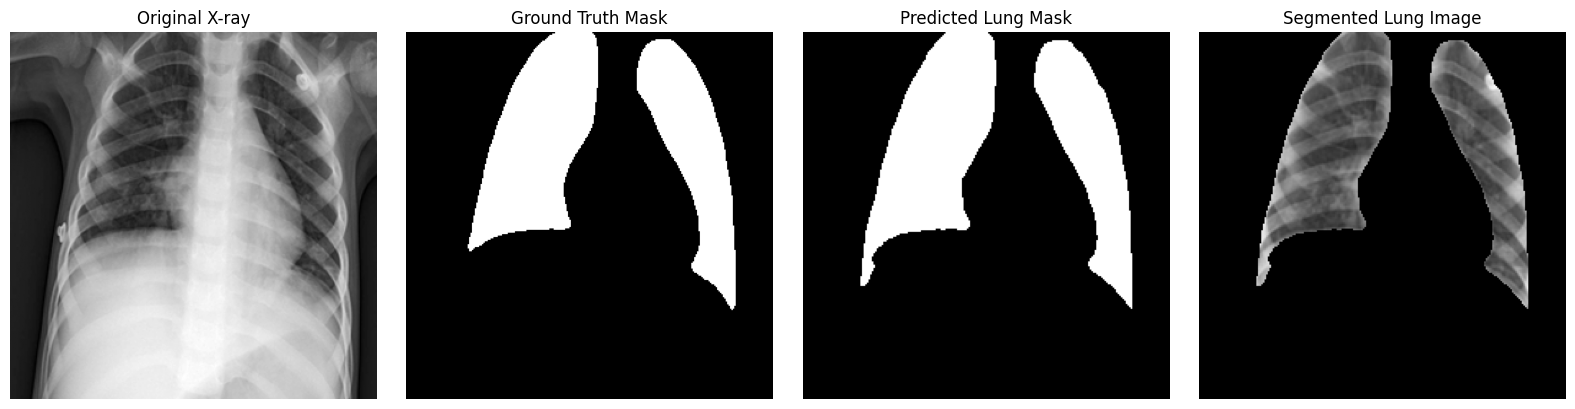

In [18]:
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torchvision import transforms

VIS_FOLD = 0
VIS_INDEX = 0

fold_val_df = df[df["fold"] == VIS_FOLD].reset_index(drop=True)
sample_row = fold_val_df.iloc[VIS_INDEX]

xray_path = sample_row["image_path"]
mask_path = sample_row["mask_path"]
seg_path = sample_row["segmented_path"]

original = Image.open(xray_path).convert("L")
ground_truth = Image.open(mask_path).convert("L")
segmented = Image.open(seg_path).convert("L")

vis_unet = UNet().to(device)

checkpoint_path = f"/kaggle/working/fold{VIS_FOLD}_unet.pth"

vis_unet.load_state_dict(
    torch.load(checkpoint_path, map_location=device)
)

vis_unet.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])

x = transform(original).unsqueeze(0).to(device)

with torch.no_grad():
    predicted_mask = (
        torch.sigmoid(vis_unet(x)) > 0.5
    ).float().squeeze().cpu().numpy()

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(original, cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(ground_truth, cmap="gray")
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Predicted Lung Mask")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(segmented, cmap="gray")
plt.title("Segmented Lung Image")
plt.axis("off")

plt.tight_layout()
plt.show()

                 precision    recall  f1-score   support

       COVID-19     0.9216    0.8740    0.8972      1143
         Normal     0.8732    0.8969    0.8849      1144
Viral Pneumonia     0.9784    0.9895    0.9839      1143
   Lung Opacity     0.8774    0.8889    0.8831      1143

       accuracy                         0.9123      4573
      macro avg     0.9126    0.9123    0.9123      4573
   weighted avg     0.9126    0.9123    0.9123      4573



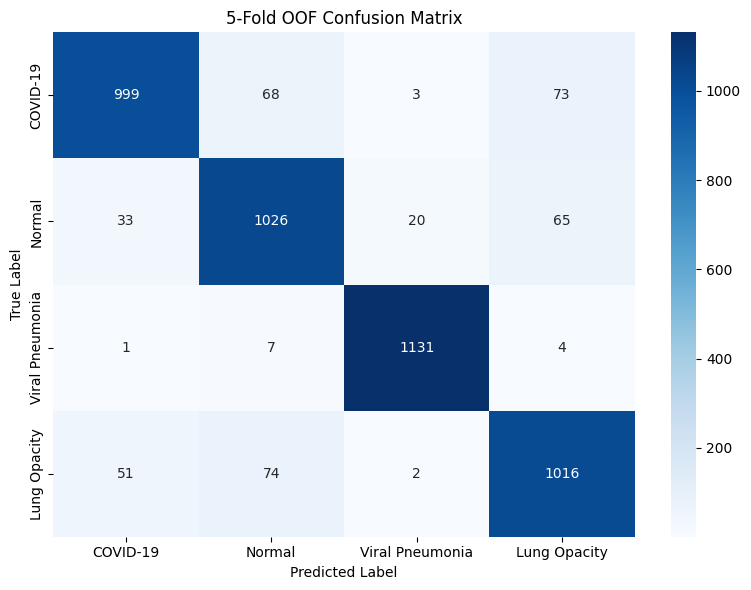

In [19]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print(classification_report(
    oof_labels,
    oof_preds,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(oof_labels, oof_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("5-Fold OOF Confusion Matrix")
plt.tight_layout()
plt.show()

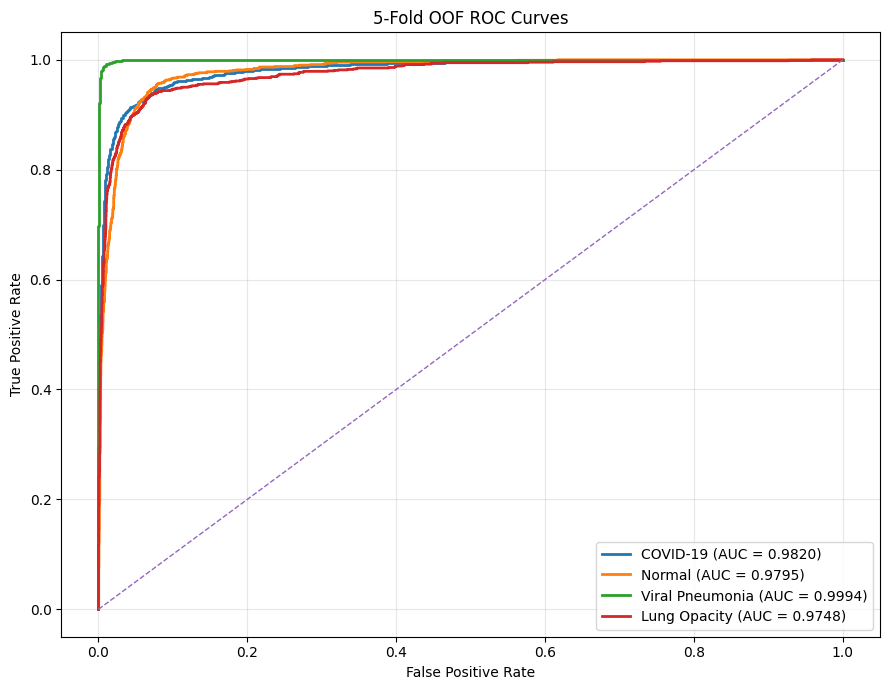

In [20]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

y_true_bin = label_binarize(oof_labels, classes=np.arange(4))

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], oof_probs[:, i])
    class_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"{class_name} (AUC = {class_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("5-Fold OOF ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

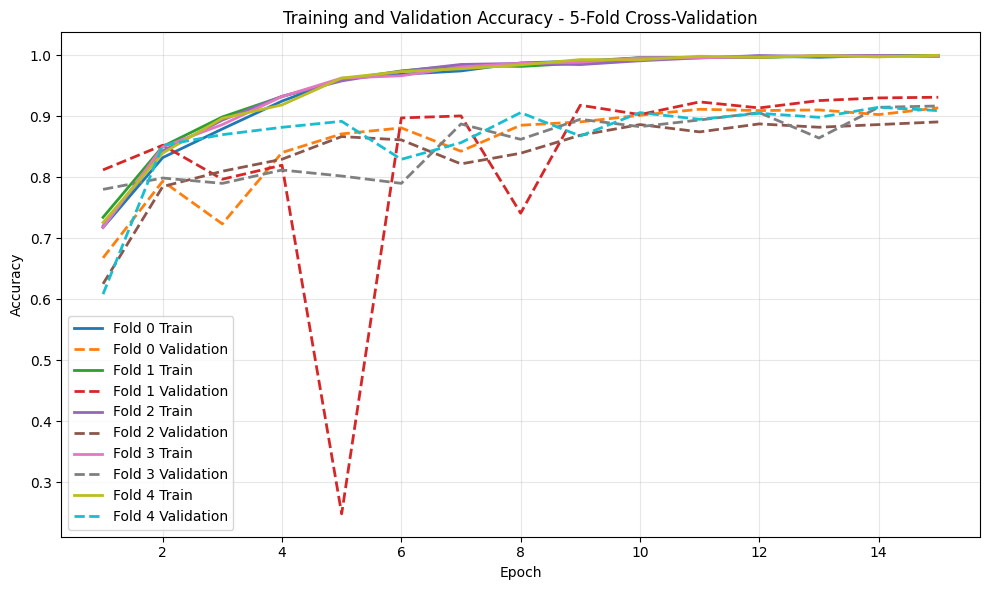

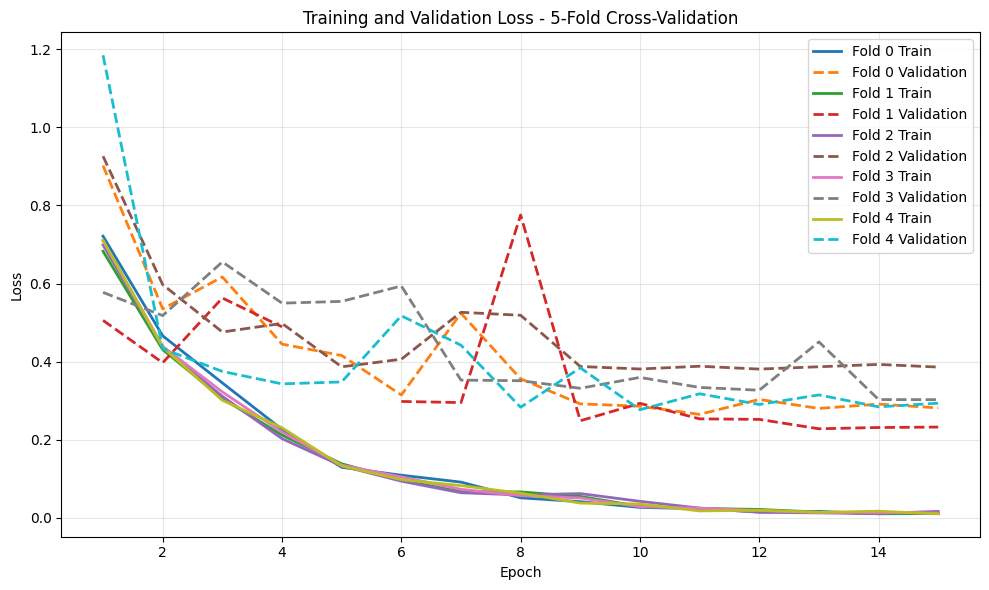

In [21]:
all_histories = histories

epochs = range(1, 16)

plt.figure(figsize=(10, 6))

for fold in range(5):
    plt.plot(
        epochs,
        all_histories[fold]["train_acc"],
        linewidth=2,
        label=f"Fold {fold} Train"
    )
    plt.plot(
        epochs,
        all_histories[fold]["val_acc"],
        linestyle="--",
        linewidth=2,
        label=f"Fold {fold} Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy - 5-Fold Cross-Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))

for fold in range(5):
    plt.plot(
        epochs,
        all_histories[fold]["train_loss"],
        linewidth=2,
        label=f"Fold {fold} Train"
    )
    plt.plot(
        epochs,
        all_histories[fold]["val_loss"],
        linestyle="--",
        linewidth=2,
        label=f"Fold {fold} Validation"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss - 5-Fold Cross-Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
oof_results_df = df.copy()

oof_results_df["true_label"] = oof_labels
oof_results_df["predicted_label"] = oof_preds
oof_results_df["predicted_class"] = [class_names[i] for i in oof_preds]

for i, class_name in enumerate(class_names):
    oof_results_df[f"prob_{class_name.replace(' ', '_')}"] = oof_probs[:, i]

results_path = "/kaggle/working/5fold_oof_results.csv"
oof_results_df.to_csv(results_path, index=False)

np.save("/kaggle/working/5fold_oof_probabilities.npy", oof_probs)
np.save("/kaggle/working/5fold_oof_predictions.npy", oof_preds)

print("OOF results saved successfully")
print(f"CSV: {results_path}")
print(f"Samples: {len(oof_results_df)}")
print(f"Probability shape: {oof_probs.shape}")
print(f"Prediction shape: {oof_preds.shape}")

OOF results saved successfully
CSV: /kaggle/working/5fold_oof_results.csv
Samples: 4573
Probability shape: (4573, 4)
Prediction shape: (4573,)


In [23]:
final_metrics = pd.DataFrame({
    "Metric": list(cv_metrics.keys()),
    "Score": list(cv_metrics.values()),
    "Percentage": [v * 100 for v in cv_metrics.values()],
})
print(final_metrics.to_string(index=False))

print("\nPer-fold accuracy:", [f"{a*100:.2f}%" for a in fold_accs])
print(f"Mean fold accuracy: {fold_accs.mean()*100:.2f}%")
print(f"Std fold accuracy : {fold_accs.std()*100:.2f}%")

   Metric    Score  Percentage
 Accuracy 0.912311   91.231139
Precision 0.912632   91.263167
   Recall 0.912315   91.231477
 F1-Score 0.912259   91.225890
  ROC-AUC 0.983935   98.393465

Per-fold accuracy: ['91.37%', '93.11%', '89.07%', '91.68%', '90.92%']
Mean fold accuracy: 91.23%
Std fold accuracy : 1.31%


In [24]:
# Per-fold metrics -> mean +/- std over the 5 validation folds
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

fold_ids = df["fold"].values
per_fold = {"Accuracy": [], "Precision": [], "Recall": [], "F1-Score": [], "ROC-AUC": []}

for f in range(5):
    m = fold_ids == f
    y, p, pr = oof_labels[m], oof_preds[m], oof_probs[m]
    per_fold["Accuracy"].append(accuracy_score(y, p))
    per_fold["Precision"].append(precision_score(y, p, average="macro"))
    per_fold["Recall"].append(recall_score(y, p, average="macro"))
    per_fold["F1-Score"].append(f1_score(y, p, average="macro"))
    per_fold["ROC-AUC"].append(roc_auc_score(y, pr, multi_class="ovr", average="macro"))

cv_summary = pd.DataFrame({
    "Mean (%)": {k: np.mean(v) * 100 for k, v in per_fold.items()},
    "Std (%)":  {k: np.std(v) * 100 for k, v in per_fold.items()},
})
cv_summary["Mean +/- Std"] = [f"{m:.2f} +/- {s:.2f}" for m, s in zip(cv_summary["Mean (%)"], cv_summary["Std (%)"])]
print(cv_summary.round(2).to_string())
cv_summary.to_csv("/kaggle/working/cv_mean_std_metrics.csv")

           Mean (%)  Std (%)    Mean +/- Std
Accuracy      91.23     1.31  91.23 +/- 1.31
Precision     91.31     1.32  91.31 +/- 1.32
Recall        91.23     1.31  91.23 +/- 1.31
F1-Score      91.23     1.31  91.23 +/- 1.31
ROC-AUC       98.43     0.39  98.43 +/- 0.39


In [25]:
from sklearn.model_selection import train_test_split

# identical call to the early split cell (same data, same seed) -> same test set; k-fold has not touched it
development_df, test_df = train_test_split(
    full_df,
    test_size=0.15,
    stratify=full_df["label"],
    random_state=42
)

development_df = development_df.copy()
test_df = test_df.copy()

assert set(test_df["image_path"]) == heldout_test_paths, "Test set differs from the one held out before k-fold!"

print(f"Development set: {len(development_df)}")
print(f"Independent test set: {len(test_df)}")

print("\nDevelopment distribution:")
print(development_df["class_name"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class_name"].value_counts().sort_index())

overlap = set(development_df["image_path"]).intersection(
    set(test_df["image_path"])
)

print(f"\nImage overlap: {len(overlap)}")

Development set: 4573
Independent test set: 807

Development distribution:
class_name
COVID              1143
Lung Opacity       1143
Normal             1144
Viral Pneumonia    1143
Name: count, dtype: int64

Test distribution:
class_name
COVID              202
Lung Opacity       202
Normal             201
Viral Pneumonia    202
Name: count, dtype: int64

Image overlap: 0


In [26]:
train_df, val_df = train_test_split(
    development_df,
    test_size=0.20,
    stratify=development_df["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train set: {len(train_df)}")
print(f"Validation set: {len(val_df)}")
print(f"Independent test set: {len(test_df)}")

print("\nTrain distribution:")
print(train_df["class_name"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["class_name"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["class_name"].value_counts().sort_index())

Train set: 3658
Validation set: 915
Independent test set: 807

Train distribution:
class_name
COVID              915
Lung Opacity       914
Normal             915
Viral Pneumonia    914
Name: count, dtype: int64

Validation distribution:
class_name
COVID              228
Lung Opacity       229
Normal             229
Viral Pneumonia    229
Name: count, dtype: int64

Test distribution:
class_name
COVID              202
Lung Opacity       202
Normal             201
Viral Pneumonia    202
Name: count, dtype: int64


In [27]:
split_df = full_df.copy()

split_df["split"] = "development"

split_df.loc[split_df["image_path"].isin(train_df["image_path"]), "split"] = "train"
split_df.loc[split_df["image_path"].isin(val_df["image_path"]), "split"] = "validation"
split_df.loc[split_df["image_path"].isin(test_df["image_path"]), "split"] = "test"

split_path = "/kaggle/working/independent_test_split.csv"
split_df.to_csv(split_path, index=False)

print("Split saved successfully")
print(f"Path: {split_path}")
print(split_df["split"].value_counts())

Split saved successfully
Path: /kaggle/working/independent_test_split.csv
split
train         3658
validation     915
test           807
Name: count, dtype: int64


In [28]:
train_seg_dataset = SegmentationDataset(train_df)
val_seg_dataset = SegmentationDataset(val_df)
test_seg_dataset = SegmentationDataset(test_df)

print(f"Segmentation train samples: {len(train_seg_dataset)}")
print(f"Segmentation validation samples: {len(val_seg_dataset)}")
print(f"Segmentation test samples: {len(test_seg_dataset)}")

sample_image, sample_mask = train_seg_dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Mask shape: {sample_mask.shape}")
print(f"Image range: {sample_image.min().item():.4f} to {sample_image.max().item():.4f}")
print(f"Mask range: {sample_mask.min().item():.4f} to {sample_mask.max().item():.4f}")

Segmentation train samples: 3658
Segmentation validation samples: 915
Segmentation test samples: 807
Image shape: torch.Size([3, 224, 224])
Mask shape: torch.Size([1, 224, 224])
Image range: 0.0000 to 0.9098
Mask range: 0.0000 to 1.0000


In [29]:
set_seed(42)   # reproducible independent run (same helper as the CV pipeline)

unet_independent = UNet().to(device)

criterion_seg = nn.BCEWithLogitsLoss()

optimizer_seg = torch.optim.AdamW(
    unet_independent.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

print(f"U-Net parameters: {sum(p.numel() for p in unet_independent.parameters()):,}")
print(f"Device: {device}")

U-Net parameters: 7,763,041
Device: cuda


In [30]:
train_seg_loader = DataLoader(
    train_seg_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_seg_loader = DataLoader(
    val_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

num_seg_epochs = 15

best_seg_dice = 0.0
seg_history = {
    "train_loss": [],
    "train_dice": [],
    "val_loss": [],
    "val_dice": []
}

for epoch in range(num_seg_epochs):
    unet_independent.train()
    train_loss = 0.0
    train_dice = 0.0

    for images, masks in train_seg_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer_seg.zero_grad()

        outputs = unet_independent(images)
        loss = segmentation_loss(outputs, masks)

        loss.backward()
        optimizer_seg.step()

        train_loss += loss.item()
        train_dice += dice_coefficient(outputs, masks).item()

    train_loss /= len(train_seg_loader)
    train_dice /= len(train_seg_loader)

    unet_independent.eval()
    val_loss = 0.0
    val_dice = 0.0

    with torch.no_grad():
        for images, masks in val_seg_loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            outputs = unet_independent(images)
            loss = segmentation_loss(outputs, masks)

            val_loss += loss.item()
            val_dice += dice_coefficient(outputs, masks).item()

    val_loss /= len(val_seg_loader)
    val_dice /= len(val_seg_loader)

    seg_history["train_loss"].append(train_loss)
    seg_history["train_dice"].append(train_dice)
    seg_history["val_loss"].append(val_loss)
    seg_history["val_dice"].append(val_dice)

    if val_dice > best_seg_dice:
        best_seg_dice = val_dice
        torch.save(
            unet_independent.state_dict(),
            "/kaggle/working/independent_best_unet.pth"
        )

    print(
        f"Epoch {epoch+1}/{num_seg_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Dice: {train_dice:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Dice: {val_dice:.4f}"
    )

print(f"\nBest Validation Dice: {best_seg_dice:.4f}")
print("Best independent U-Net saved successfully")

Epoch 1/15 | Train Loss: 0.3561 | Train Dice: 0.8935 | Val Loss: 0.2872 | Val Dice: 0.9484
Epoch 2/15 | Train Loss: 0.2573 | Train Dice: 0.9544 | Val Loss: 0.2312 | Val Dice: 0.9607
Epoch 3/15 | Train Loss: 0.2064 | Train Dice: 0.9646 | Val Loss: 0.1924 | Val Dice: 0.9548
Epoch 4/15 | Train Loss: 0.1676 | Train Dice: 0.9683 | Val Loss: 0.1547 | Val Dice: 0.9662
Epoch 5/15 | Train Loss: 0.1352 | Train Dice: 0.9726 | Val Loss: 0.1224 | Val Dice: 0.9722
Epoch 6/15 | Train Loss: 0.1091 | Train Dice: 0.9762 | Val Loss: 0.1048 | Val Dice: 0.9734
Epoch 7/15 | Train Loss: 0.0889 | Train Dice: 0.9787 | Val Loss: 0.0845 | Val Dice: 0.9749
Epoch 8/15 | Train Loss: 0.0735 | Train Dice: 0.9804 | Val Loss: 0.0733 | Val Dice: 0.9762
Epoch 9/15 | Train Loss: 0.0624 | Train Dice: 0.9810 | Val Loss: 0.0639 | Val Dice: 0.9749
Epoch 10/15 | Train Loss: 0.0529 | Train Dice: 0.9826 | Val Loss: 0.0568 | Val Dice: 0.9760
Epoch 11/15 | Train Loss: 0.0454 | Train Dice: 0.9837 | Val Loss: 0.0496 | Val Dice: 0.97

In [31]:
unet_independent.load_state_dict(
    torch.load(
        "/kaggle/working/independent_best_unet.pth",
        map_location=device
    )
)

unet_independent.eval()

segmented_root = "/kaggle/working/independent_segmented"
os.makedirs(segmented_root, exist_ok=True)

def generate_segmented_images(dataframe, split_name):
    split_dir = os.path.join(segmented_root, split_name)
    os.makedirs(split_dir, exist_ok=True)

    loader = DataLoader(
        SegmentationDataset(dataframe),
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    paths = []

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device, non_blocking=True)

            outputs = unet_independent(images)
            masks = (torch.sigmoid(outputs) > 0.5).float()

            segmented = images * masks

            for image_tensor in segmented:
                image_tensor = image_tensor.mean(dim=0)
                image_tensor = image_tensor.clamp(0, 1)
                image_array = (image_tensor.cpu().numpy() * 255).astype(np.uint8)

                filename = f"{len(paths):05d}.png"
                save_path = os.path.join(split_dir, filename)

                Image.fromarray(image_array).save(save_path)
                paths.append(save_path)

    return paths

train_segmented_paths = generate_segmented_images(train_df, "train")
val_segmented_paths = generate_segmented_images(val_df, "validation")
test_segmented_paths = generate_segmented_images(test_df, "test")

train_df["independent_segmented_path"] = train_segmented_paths
val_df["independent_segmented_path"] = val_segmented_paths
test_df["independent_segmented_path"] = test_segmented_paths

print(f"Train segmented images: {len(train_segmented_paths)}")
print(f"Validation segmented images: {len(val_segmented_paths)}")
print(f"Test segmented images: {len(test_segmented_paths)}")
print(f"Segmented directory: {segmented_root}")

Train segmented images: 3658
Validation segmented images: 915
Test segmented images: 807
Segmented directory: /kaggle/working/independent_segmented


In [32]:
test_seg_loader = DataLoader(
    test_seg_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

unet_independent.eval()
test_dice = 0.0
n_test = 0

with torch.no_grad():
    for images, masks in test_seg_loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        outputs = unet_independent(images)
        d = dice_coefficient(outputs, masks).item()

        test_dice += d * images.size(0)   # weight by batch size -> exact mean over all test images
        n_test += images.size(0)

test_dice /= n_test

print(f"Test images      : {n_test}")
print(f"U-Net Validation Dice (best): {best_seg_dice:.4f} ({best_seg_dice*100:.2f}%)")
print(f"U-Net Test Dice             : {test_dice:.4f} ({test_dice*100:.2f}%)")

Test images      : 807
U-Net Validation Dice (best): 0.9799 (97.99%)
U-Net Test Dice             : 0.9804 (98.04%)


In [33]:
class SegmentedIndependentDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((224, 224)),
            transforms.Grayscale(num_output_channels=3),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["independent_segmented_path"]).convert("L")
        image = self.transform(image)
        label = int(row["label"])
        return image, label

train_cls_dataset = SegmentedIndependentDataset(train_df)
val_cls_dataset = SegmentedIndependentDataset(val_df)
test_cls_dataset = SegmentedIndependentDataset(test_df)

print(f"Classification train samples: {len(train_cls_dataset)}")
print(f"Classification validation samples: {len(val_cls_dataset)}")
print(f"Classification test samples: {len(test_cls_dataset)}")

sample_image, sample_label = train_cls_dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Label: {sample_label}")
print(f"Image range: {sample_image.min().item():.4f} to {sample_image.max().item():.4f}")

Classification train samples: 3658
Classification validation samples: 915
Classification test samples: 807
Image shape: torch.Size([3, 224, 224])
Label: 1
Image range: -2.1179 to 1.9603


In [34]:
train_cls_loader = DataLoader(
    train_cls_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_cls_loader = DataLoader(
    val_cls_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_cls_loader = DataLoader(
    test_cls_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(train_cls_loader))

print(f"Batch image shape: {images.shape}")
print(f"Batch label shape: {labels.shape}")
print(f"Batch labels: {labels.tolist()}")

Batch image shape: torch.Size([16, 3, 224, 224])
Batch label shape: torch.Size([16])
Batch labels: [1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 2, 0, 1, 2, 0, 3]


In [35]:
set_seed(42)   # reproducible independent run

independent_model = ConvNeXtRepViT(num_classes=4).to(device)

criterion_cls = nn.CrossEntropyLoss()

optimizer_cls = torch.optim.AdamW(
    independent_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler_cls = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_cls,
    T_max=15,
    eta_min=1e-6
)

print(f"Total parameters: {sum(p.numel() for p in independent_model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in independent_model.parameters() if p.requires_grad):,}")
print(f"Device: {device}")

Total parameters: 33,258,068
Trainable parameters: 33,258,068
Device: cuda


In [36]:
num_cls_epochs = 15

best_val_acc = 0.0

cls_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

scaler_cls = torch.amp.GradScaler("cuda")

for epoch in range(num_cls_epochs):
    independent_model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_cls_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_cls.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):
            outputs = independent_model(images)
            loss = criterion_cls(outputs, labels)

        scaler_cls.scale(loss).backward()
        scaler_cls.step(optimizer_cls)
        scaler_cls.update()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    independent_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_cls_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast("cuda"):
                outputs = independent_model(images)
                loss = criterion_cls(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    scheduler_cls.step()

    cls_history["train_loss"].append(train_loss)
    cls_history["train_acc"].append(train_acc)
    cls_history["val_loss"].append(val_loss)
    cls_history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(
            independent_model.state_dict(),
            "/kaggle/working/independent_best_classifier.pth"
        )

    print(
        f"Epoch {epoch+1}/{num_cls_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {optimizer_cls.param_groups[0]['lr']:.6f}"
    )

print(f"\nBest Validation Accuracy: {best_val_acc:.4f}")
print("Best independent classifier saved successfully")

Epoch 1/15 | Train Loss: 0.6989 | Train Acc: 0.7288 | Val Loss: 0.6279 | Val Acc: 0.7432 | LR: 0.000099
Epoch 2/15 | Train Loss: 0.4509 | Train Acc: 0.8360 | Val Loss: 1.1467 | Val Acc: 0.5148 | LR: 0.000096
Epoch 3/15 | Train Loss: 0.2942 | Train Acc: 0.9040 | Val Loss: 0.3572 | Val Acc: 0.8787 | LR: 0.000091
Epoch 4/15 | Train Loss: 0.2319 | Train Acc: 0.9215 | Val Loss: 0.3485 | Val Acc: 0.8863 | LR: 0.000084
Epoch 5/15 | Train Loss: 0.1456 | Train Acc: 0.9582 | Val Loss: 0.3649 | Val Acc: 0.8743 | LR: 0.000075
Epoch 6/15 | Train Loss: 0.0947 | Train Acc: 0.9751 | Val Loss: 0.8947 | Val Acc: 0.6820 | LR: 0.000066
Epoch 7/15 | Train Loss: 0.0756 | Train Acc: 0.9811 | Val Loss: 0.3650 | Val Acc: 0.8765 | LR: 0.000056
Epoch 8/15 | Train Loss: 0.0406 | Train Acc: 0.9918 | Val Loss: 0.2935 | Val Acc: 0.9060 | LR: 0.000045
Epoch 9/15 | Train Loss: 0.0418 | Train Acc: 0.9893 | Val Loss: 0.3498 | Val Acc: 0.8896 | LR: 0.000035
Epoch 10/15 | Train Loss: 0.0241 | Train Acc: 0.9967 | Val Loss:

In [37]:
# Load the BEST-validation checkpoint (the training loop above leaves the LAST-epoch weights in memory)
independent_model.load_state_dict(
    torch.load("/kaggle/working/independent_best_classifier.pth", map_location=device)
)
independent_model.eval()

_labels, _preds, _probs = [], [], []

with torch.no_grad():
    for images, labels in test_cls_loader:
        images = images.to(device, non_blocking=True)

        with torch.amp.autocast("cuda"):
            outputs = independent_model(images)

        probs = torch.softmax(outputs.float(), dim=1)
        _probs.append(probs.cpu().numpy())
        _preds.append(probs.argmax(dim=1).cpu().numpy())
        _labels.append(labels.numpy())

test_labels = np.concatenate(_labels)
test_preds  = np.concatenate(_preds)
test_probs  = np.concatenate(_probs)

print("Test samples:", len(test_labels))
print("Probabilities shape:", test_probs.shape)
print(f"Quick test accuracy: {(test_preds == test_labels).mean()*100:.2f}%")

Test samples: 807
Probabilities shape: (807, 4)
Quick test accuracy: 91.57%


In [38]:
test_probs = np.asarray(test_probs, dtype=np.float64)
test_probs = test_probs / test_probs.sum(axis=1, keepdims=True)

test_accuracy = accuracy_score(test_labels, test_preds)

test_precision = precision_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    test_labels,
    test_preds,
    average="macro",
    zero_division=0
)

test_roc_auc = roc_auc_score(
    test_labels,
    test_probs,
    multi_class="ovr",
    average="macro"
)

print("Independent Test Results")
print(f"Accuracy : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Precision: {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"Recall   : {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"F1-Score : {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"ROC-AUC  : {test_roc_auc:.4f} ({test_roc_auc*100:.2f}%)")

print("\nClassification Report")
print(
    classification_report(
        test_labels,
        test_preds,
        target_names=[
            "COVID-19",
            "Normal",
            "Viral Pneumonia",
            "Lung Opacity"
        ],
        digits=4
    )
)

print("Confusion Matrix")
print(confusion_matrix(test_labels, test_preds))

print("\nProbability verification")
print(f"Minimum row sum: {test_probs.sum(axis=1).min():.10f}")
print(f"Maximum row sum: {test_probs.sum(axis=1).max():.10f}")

Independent Test Results
Accuracy : 0.9157 (91.57%)
Precision: 0.9154 (91.54%)
Recall   : 0.9157 (91.57%)
F1-Score : 0.9154 (91.54%)
ROC-AUC  : 0.9862 (98.62%)

Classification Report
                 precision    recall  f1-score   support

       COVID-19     0.9167    0.9257    0.9212       202
         Normal     0.8867    0.8955    0.8911       201
Viral Pneumonia     0.9612    0.9802    0.9706       202
   Lung Opacity     0.8969    0.8614    0.8788       202

       accuracy                         0.9157       807
      macro avg     0.9154    0.9157    0.9154       807
   weighted avg     0.9154    0.9157    0.9154       807

Confusion Matrix
[[187   6   1   8]
 [  5 180   6  10]
 [  0   2 198   2]
 [ 12  15   1 174]]

Probability verification
Minimum row sum: 1.0000000000
Maximum row sum: 1.0000000000


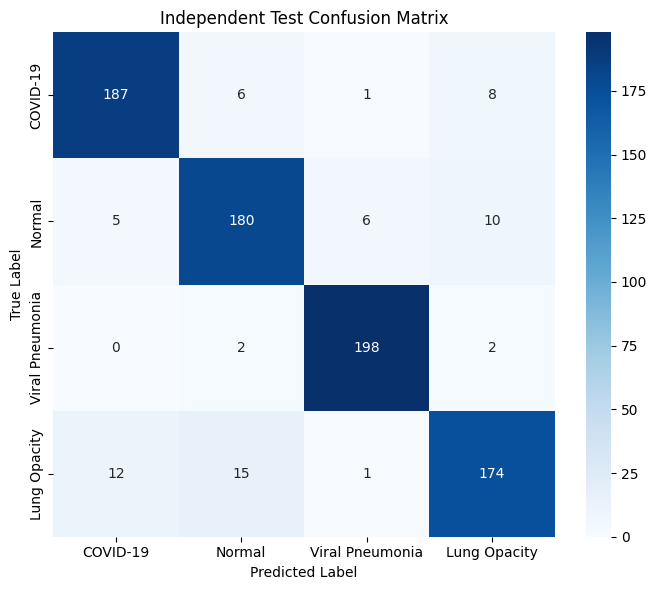

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(test_labels, test_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"],
    yticklabels=["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Independent Test Confusion Matrix")
plt.tight_layout()
plt.show()

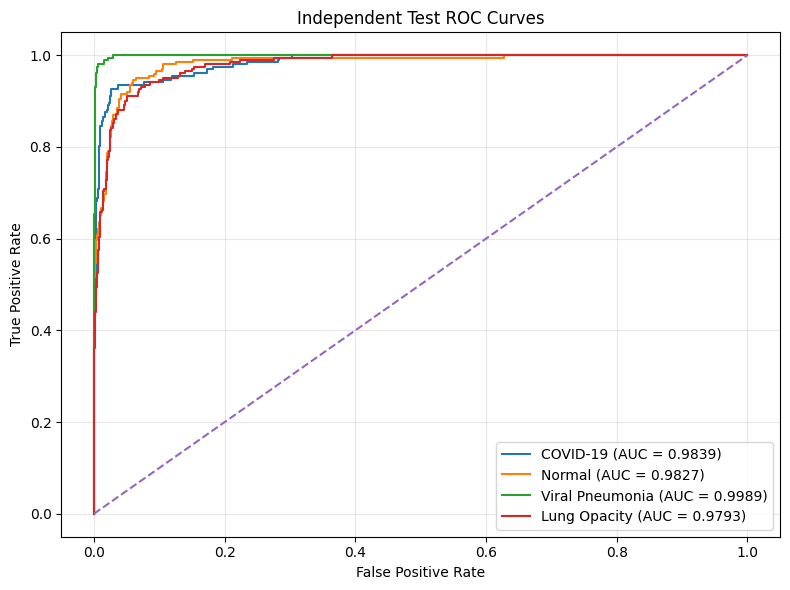

In [40]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

class_names = [
    "COVID-19",
    "Normal",
    "Viral Pneumonia",
    "Lung Opacity"
]

test_labels_bin = label_binarize(
    test_labels,
    classes=[0, 1, 2, 3]
)

plt.figure(figsize=(8, 6))

for i in range(4):
    fpr, tpr, _ = roc_curve(
        test_labels_bin[:, i],
        test_probs[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_names[i]} (AUC = {roc_auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Independent Test ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

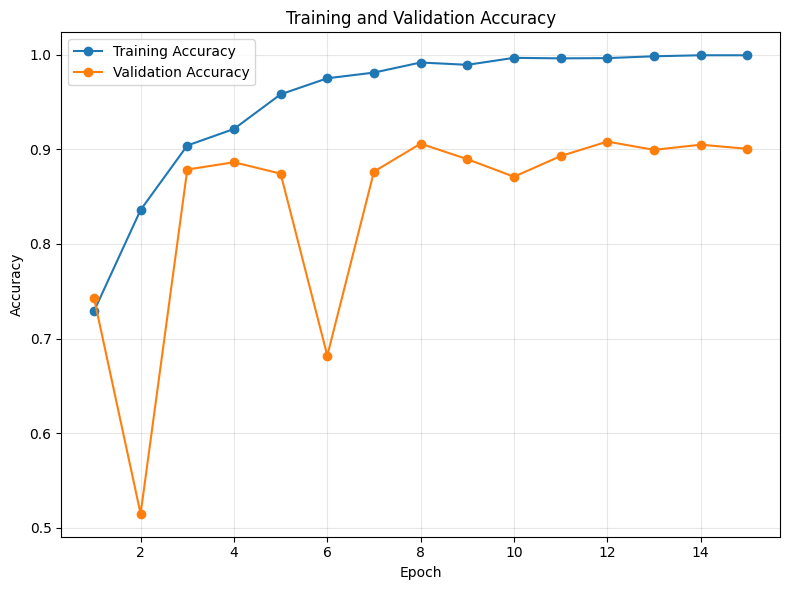

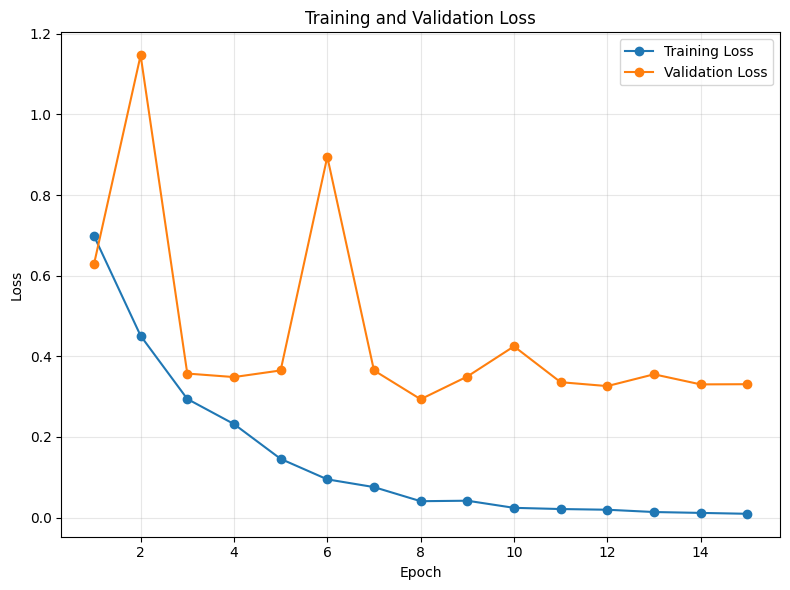

In [41]:
epochs = range(1, len(cls_history["train_acc"]) + 1)

plt.figure(figsize=(8, 6))

plt.plot(
    epochs,
    cls_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    cls_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))

plt.plot(
    epochs,
    cls_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    cls_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [42]:
results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        test_accuracy,
        test_precision,
        test_recall,
        test_f1,
        test_roc_auc
    ],
    "Percentage": [
        test_accuracy * 100,
        test_precision * 100,
        test_recall * 100,
        test_f1 * 100,
        test_roc_auc * 100
    ]
})

results_path = "/kaggle/working/independent_test_results.csv"
results_df.to_csv(results_path, index=False)

report = classification_report(
    test_labels,
    test_preds,
    target_names=[
        "COVID-19",
        "Normal",
        "Viral Pneumonia",
        "Lung Opacity"
    ],
    digits=4,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()
report_path = "/kaggle/working/independent_classification_report.csv"
report_df.to_csv(report_path)

cm_df = pd.DataFrame(
    confusion_matrix(test_labels, test_preds),
    index=["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"],
    columns=["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"]
)

cm_path = "/kaggle/working/independent_confusion_matrix.csv"
cm_df.to_csv(cm_path)

torch.save(
    independent_model.state_dict(),
    "/kaggle/working/final_independent_convnext_repvIT.pth"
)

print("Final independent evaluation artifacts saved")
print(f"Results: {results_path}")
print(f"Classification report: {report_path}")
print(f"Confusion matrix: {cm_path}")
print("Model: /kaggle/working/final_independent_convnext_repvIT.pth")
print(f"\nIndependent Test Accuracy: {test_accuracy*100:.2f}%")
print(f"Independent Test ROC-AUC: {test_roc_auc*100:.2f}%")

Final independent evaluation artifacts saved
Results: /kaggle/working/independent_test_results.csv
Classification report: /kaggle/working/independent_classification_report.csv
Confusion matrix: /kaggle/working/independent_confusion_matrix.csv
Model: /kaggle/working/final_independent_convnext_repvIT.pth

Independent Test Accuracy: 91.57%
Independent Test ROC-AUC: 98.62%


In [43]:
import torch.nn.functional as F
import cv2

class_names = ["COVID-19", "Normal", "Viral Pneumonia", "Lung Opacity"]

class BranchGradCAM:
    """Grad-CAM on the last stage of one backbone (tensor hook, safe with in-place ops)."""
    def __init__(self, module):
        self.acts, self.grads = None, None
        self.handle = module.register_forward_hook(self._fwd)

    def _fwd(self, module, inputs, output):
        assert output.dim() == 4, f"Expected NCHW feature map, got {tuple(output.shape)}"
        self.acts = output
        if output.requires_grad:
            output.register_hook(lambda g: setattr(self, "grads", g))

    def cam(self, size=224):
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        c = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        c = F.interpolate(c, size=(size, size), mode="bilinear", align_corners=False)
        c = c.squeeze().detach().cpu().numpy()
        c = c - c.min()
        return c / c.max() if c.max() > 0 else c

gc_convnext = BranchGradCAM(independent_model.convnext.stages[-1])
gc_repvit   = BranchGradCAM(independent_model.repvit.stages[-1])

MEAN, STD = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])

def explain(tensor):
    """Returns predicted class, and Grad-CAMs for ConvNeXt, RepViT and their average (fused)."""
    independent_model.eval()
    independent_model.zero_grad(set_to_none=True)
    out = independent_model(tensor.unsqueeze(0).to(device))      # fp32, gradients enabled
    pred = out.argmax(dim=1).item()
    out[0, pred].backward()
    cams = {"ConvNeXt": gc_convnext.cam(), "RepViT": gc_repvit.cam()}
    cams["Fused"] = (cams["ConvNeXt"] + cams["RepViT"]) / 2
    return pred, cams

def to_gray(tensor):
    return np.clip((tensor.permute(1, 2, 0).numpy() * STD + MEAN)[..., 0], 0, 1)

def overlay(gray, cam, alpha=0.4):
    heat = cv2.cvtColor(cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
    base = cv2.cvtColor(np.uint8(255 * gray), cv2.COLOR_GRAY2RGB)
    return cv2.addWeighted(base, 1 - alpha, heat, alpha, 0)

print("Grad-CAM hooks registered on ConvNeXt and RepViT (last stage of each)")

Grad-CAM hooks registered on ConvNeXt and RepViT (last stage of each)


True Class: Viral Pneumonia
Predicted Class: Lung Opacity


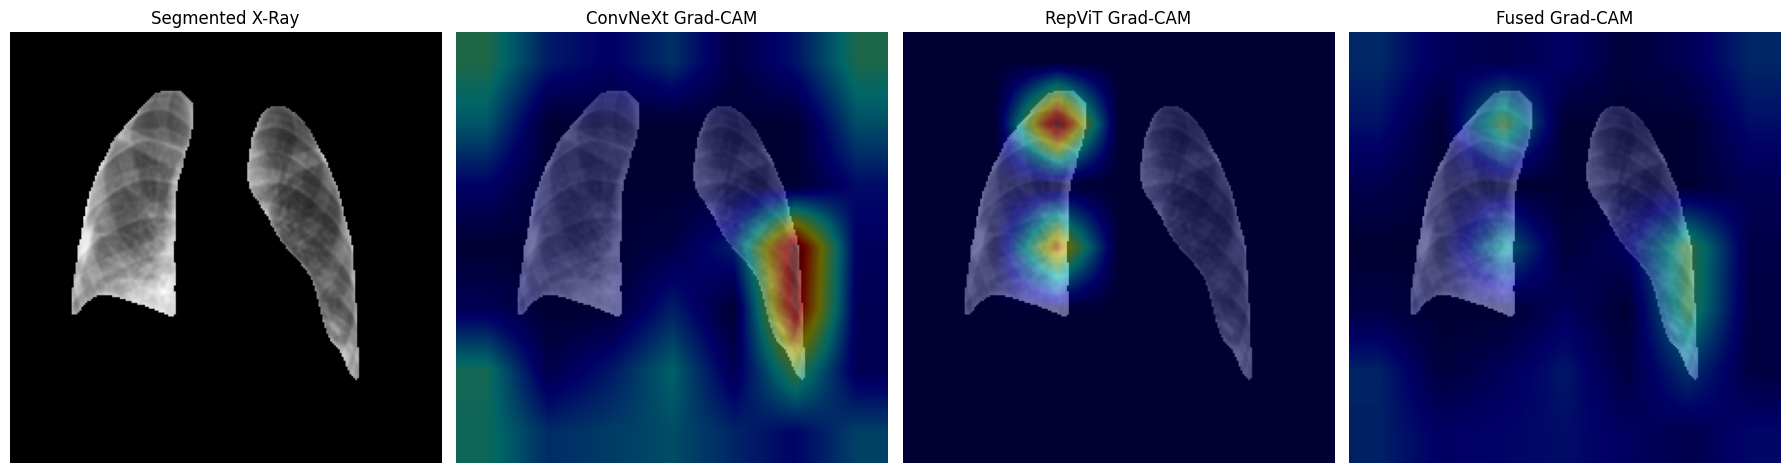

In [44]:
test_index = 0
image_tensor, true_label = test_cls_dataset[test_index]
predicted_label, cams = explain(image_tensor)
gray = to_gray(image_tensor)

print(f"True Class: {class_names[true_label]}")
print(f"Predicted Class: {class_names[predicted_label]}")

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(gray, cmap="gray");                   axes[0].set_title("Segmented X-Ray")
axes[1].imshow(overlay(gray, cams["ConvNeXt"]));     axes[1].set_title("ConvNeXt Grad-CAM")
axes[2].imshow(overlay(gray, cams["RepViT"]));       axes[2].set_title("RepViT Grad-CAM")
axes[3].imshow(overlay(gray, cams["Fused"]));        axes[3].set_title("Fused Grad-CAM")
for a in axes: a.axis("off")
plt.tight_layout()
plt.show()

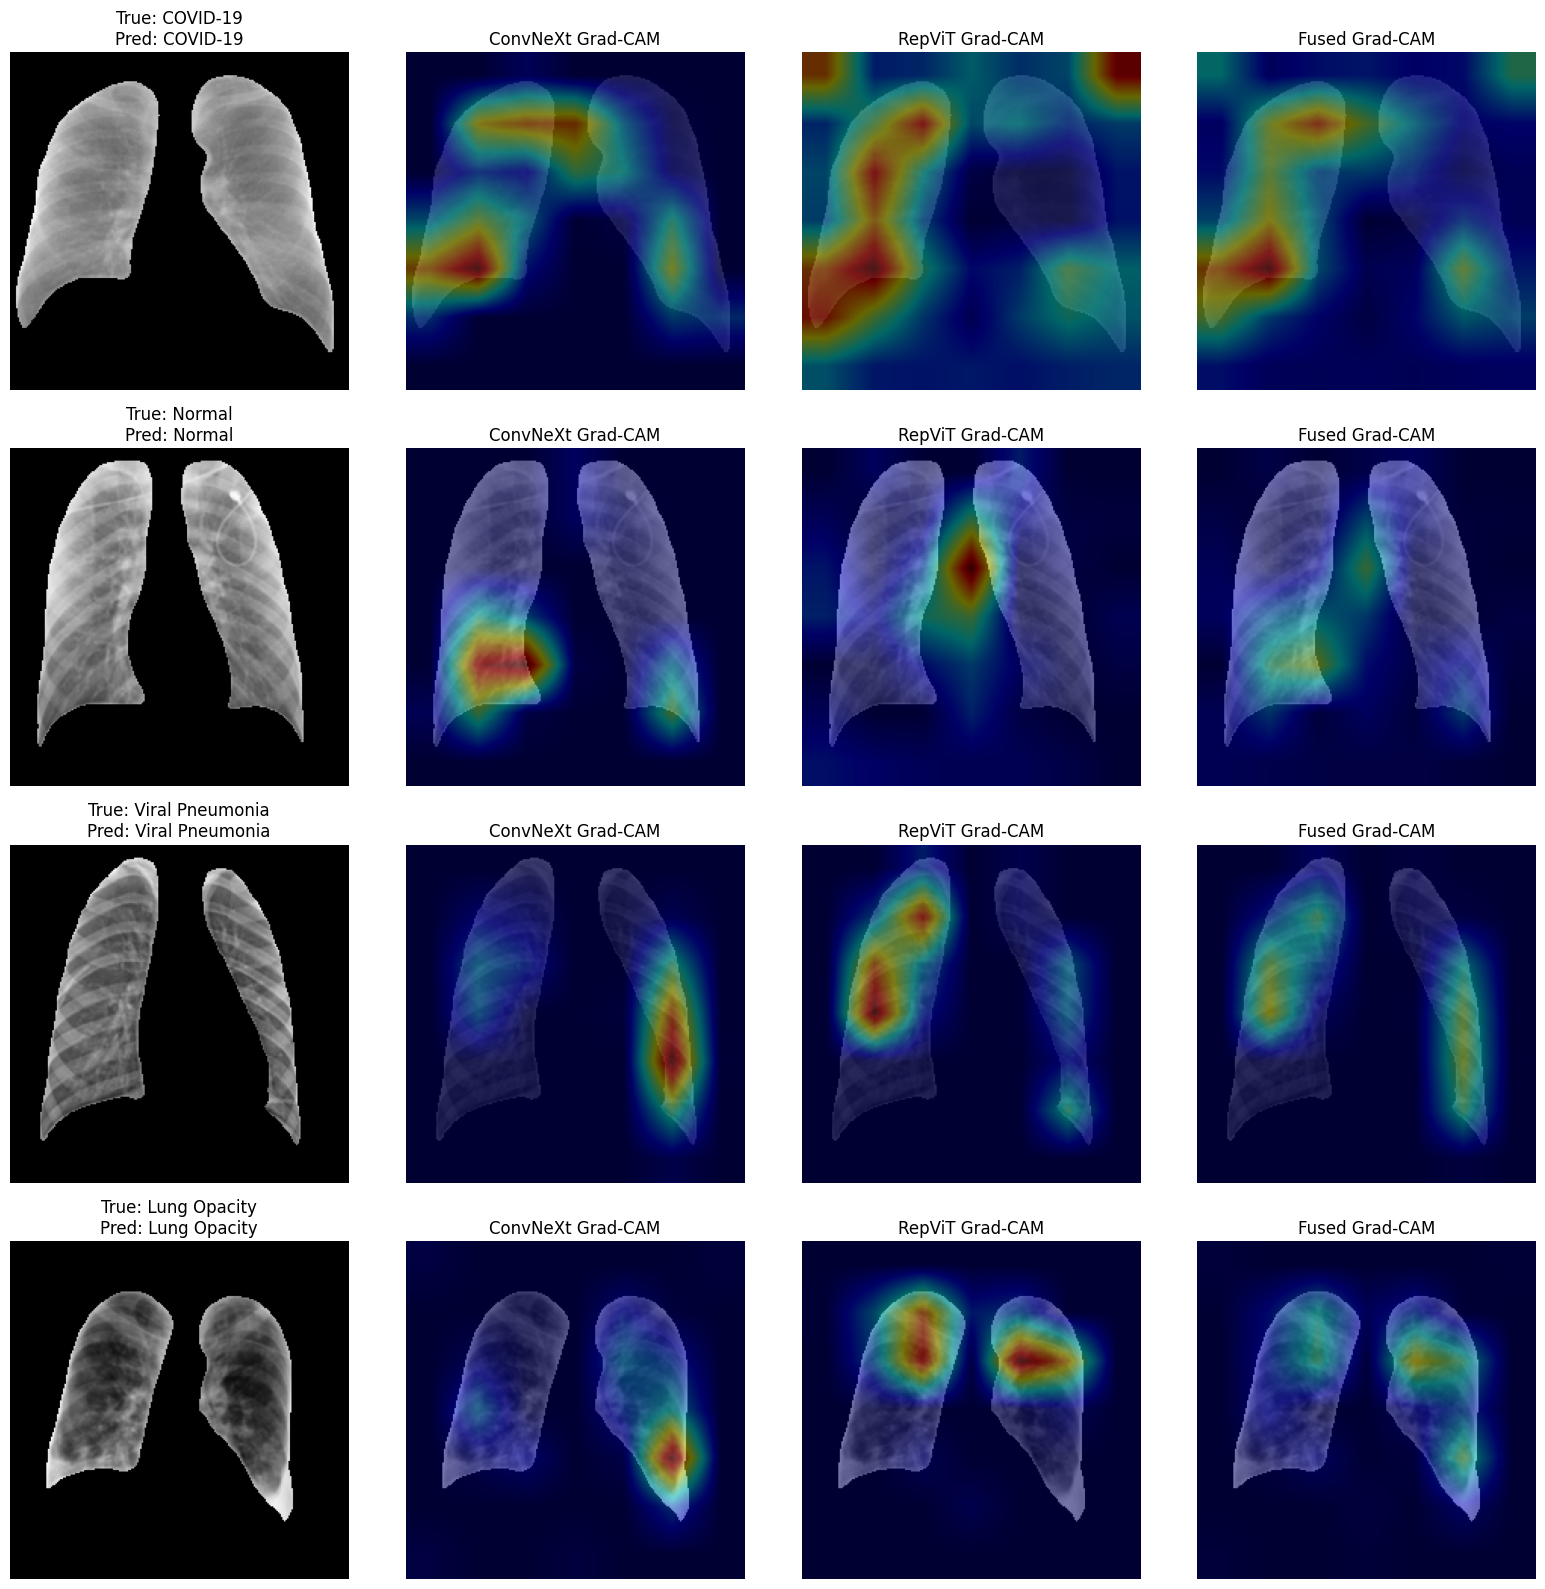

In [45]:
selected_indices = []
for class_id in range(4):
    idx = np.where(test_labels == class_id)[0]
    correct = [i for i in idx if test_preds[i] == class_id]      # prefer a correctly classified example
    selected_indices.append(int((correct if correct else idx)[0]))

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for row, test_index in enumerate(selected_indices):
    image_tensor, true_label = test_cls_dataset[test_index]
    predicted_label, cams = explain(image_tensor)
    gray = to_gray(image_tensor)

    axes[row, 0].imshow(gray, cmap="gray")
    axes[row, 0].set_title(f"True: {class_names[true_label]}\nPred: {class_names[predicted_label]}")
    axes[row, 1].imshow(overlay(gray, cams["ConvNeXt"])); axes[row, 1].set_title("ConvNeXt Grad-CAM")
    axes[row, 2].imshow(overlay(gray, cams["RepViT"]));   axes[row, 2].set_title("RepViT Grad-CAM")
    axes[row, 3].imshow(overlay(gray, cams["Fused"]));    axes[row, 3].set_title("Fused Grad-CAM")
    for a in axes[row]: a.axis("off")

plt.tight_layout()
plt.show()

In [46]:
gradcam_dir = "/kaggle/working/gradcam_results"
os.makedirs(gradcam_dir, exist_ok=True)

for class_id, test_index in enumerate(selected_indices):
    image_tensor, true_label = test_cls_dataset[test_index]
    predicted_label, cams = explain(image_tensor)
    gray = to_gray(image_tensor)

    base = cv2.cvtColor(np.uint8(255 * gray), cv2.COLOR_GRAY2RGB)
    combined = np.hstack([base,
                          overlay(gray, cams["ConvNeXt"]),
                          overlay(gray, cams["RepViT"]),
                          overlay(gray, cams["Fused"])])

    save_path = os.path.join(gradcam_dir, f"{class_names[class_id].replace(' ', '_')}.png")
    Image.fromarray(combined).save(save_path)
    print(f"{class_names[class_id]} | True: {class_names[true_label]} | "
          f"Predicted: {class_names[predicted_label]} | Saved: {save_path}")

print(f"\nGrad-CAM results directory: {gradcam_dir}")

COVID-19 | True: COVID-19 | Predicted: COVID-19 | Saved: /kaggle/working/gradcam_results/COVID-19.png
Normal | True: Normal | Predicted: Normal | Saved: /kaggle/working/gradcam_results/Normal.png
Viral Pneumonia | True: Viral Pneumonia | Predicted: Viral Pneumonia | Saved: /kaggle/working/gradcam_results/Viral_Pneumonia.png
Lung Opacity | True: Lung Opacity | Predicted: Lung Opacity | Saved: /kaggle/working/gradcam_results/Lung_Opacity.png

Grad-CAM results directory: /kaggle/working/gradcam_results


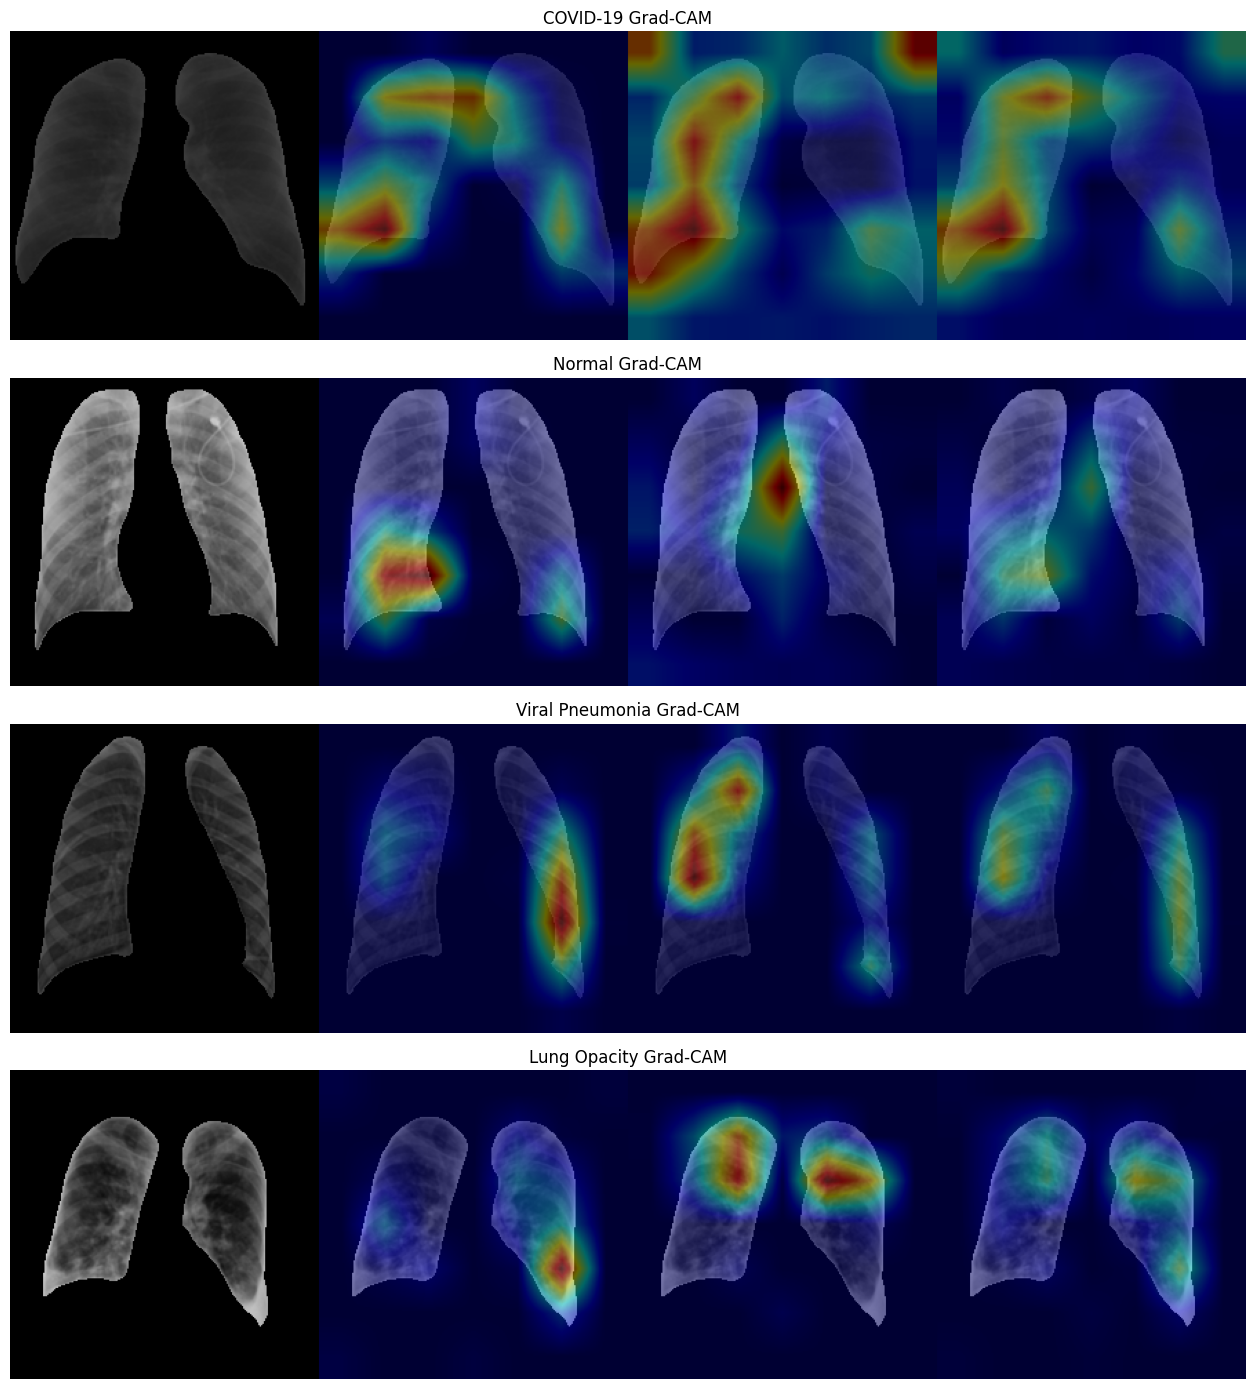

In [47]:
fig, axes = plt.subplots(4, 1, figsize=(15, 14))

for class_id in range(4):
    path = os.path.join(
        gradcam_dir,
        f"{class_names[class_id].replace(' ', '_')}.png"
    )

    image = Image.open(path)

    axes[class_id].imshow(image)
    axes[class_id].set_title(
        f"{class_names[class_id]} Grad-CAM"
    )
    axes[class_id].axis("off")

plt.tight_layout()
plt.show()

In [48]:
final_metrics_test = {
    "Accuracy":  accuracy_score(test_labels, test_preds),
    "Precision": precision_score(test_labels, test_preds, average="macro", zero_division=0),
    "Recall":    recall_score(test_labels, test_preds, average="macro", zero_division=0),
    "F1-Score":  f1_score(test_labels, test_preds, average="macro", zero_division=0),
    "ROC-AUC":   roc_auc_score(test_labels, test_probs, multi_class="ovr", average="macro"),
}

print("Final Independent Test Performance")
print("=" * 45)
for metric, value in final_metrics_test.items():
    print(f"{metric:<15}: {value:.4f} ({value * 100:.2f}%)")

print("\nTest Samples:", len(test_labels))
print("Number of Classes:", len(class_names))
print("Model: ConvNeXt Tiny + RepViT M1")
print("Segmentation: U-Net")
print("Explainability: Grad-CAM")

Final Independent Test Performance
Accuracy       : 0.9157 (91.57%)
Precision      : 0.9154 (91.54%)
Recall         : 0.9157 (91.57%)
F1-Score       : 0.9154 (91.54%)
ROC-AUC        : 0.9862 (98.62%)

Test Samples: 807
Number of Classes: 4
Model: ConvNeXt Tiny + RepViT M1
Segmentation: U-Net
Explainability: Grad-CAM


In [49]:
metrics_df = pd.DataFrame(
    {
        "Metric": list(final_metrics_test.keys()),
        "Score": list(final_metrics_test.values()),
        "Percentage": [value * 100 for value in final_metrics_test.values()]
    }
)

metrics_path = "/kaggle/working/final_independent_test_metrics.csv"

metrics_df.to_csv(metrics_path, index=False)

print(metrics_df.to_string(index=False))
print(f"\nSaved: {metrics_path}")

   Metric    Score  Percentage
 Accuracy 0.915737   91.573730
Precision 0.915360   91.535961
   Recall 0.915712   91.571228
 F1-Score 0.915412   91.541187
  ROC-AUC 0.986212   98.621231

Saved: /kaggle/working/final_independent_test_metrics.csv


In [50]:
comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "5-Fold OOF": [v * 100 for v in cv_metrics.values()],
    "Independent Test": [v * 100 for v in final_metrics_test.values()],
})

print(comparison_df.round(2).to_string(index=False))

comparison_df.to_csv("/kaggle/working/cv_vs_independent_test.csv", index=False)
print("\nSaved: /kaggle/working/cv_vs_independent_test.csv")

   Metric  5-Fold OOF  Independent Test
 Accuracy       91.23             91.57
Precision       91.26             91.54
   Recall       91.23             91.57
 F1-Score       91.23             91.54
  ROC-AUC       98.39             98.62

Saved: /kaggle/working/cv_vs_independent_test.csv


In [51]:
final_report = classification_report(
    test_labels,
    test_preds,
    target_names=class_names,
    output_dict=True
)

per_class_df = pd.DataFrame(final_report).T

per_class_df = per_class_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
]

per_class_df.columns = [
    "Precision",
    "Recall",
    "F1-Score",
    "Support"
]

print(per_class_df.to_string())

per_class_df.to_csv(
    "/kaggle/working/final_per_class_metrics.csv"
)

print("\nSaved: /kaggle/working/final_per_class_metrics.csv")

                 Precision    Recall  F1-Score  Support
COVID-19          0.916667  0.925743  0.921182    202.0
Normal            0.886700  0.895522  0.891089    201.0
Viral Pneumonia   0.961165  0.980198  0.970588    202.0
Lung Opacity      0.896907  0.861386  0.878788    202.0

Saved: /kaggle/working/final_per_class_metrics.csv


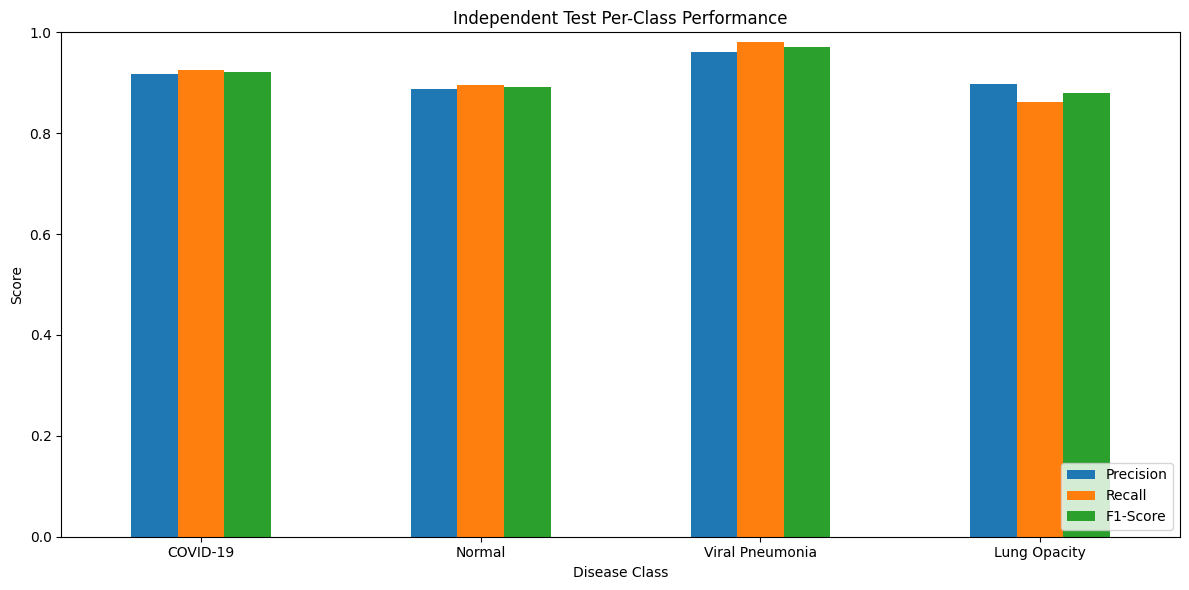

In [52]:
plot_df = per_class_df[["Precision", "Recall", "F1-Score"]]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Independent Test Per-Class Performance")
ax.set_xlabel("Disease Class")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [53]:
summary_df = pd.DataFrame({
    "Stage": ["U-Net Segmentation", "5-Fold Cross-Validation", "Independent Test"],
    "Accuracy":  [np.nan, cv_metrics["Accuracy"]*100,  final_metrics_test["Accuracy"]*100],
    "Precision": [np.nan, cv_metrics["Precision"]*100, final_metrics_test["Precision"]*100],
    "Recall":    [np.nan, cv_metrics["Recall"]*100,    final_metrics_test["Recall"]*100],
    "F1-Score":  [np.nan, cv_metrics["F1-Score"]*100,  final_metrics_test["F1-Score"]*100],
    "ROC-AUC":   [np.nan, cv_metrics["ROC-AUC"]*100,   final_metrics_test["ROC-AUC"]*100],
    "Dice (val)":  [best_seg_dice*100, np.nan, np.nan],
    "Dice (test)": [test_dice*100, np.nan, np.nan],
})

summary_path = "/kaggle/working/final_project_results_summary.csv"
summary_df.to_csv(summary_path, index=False)

print(summary_df.round(2).to_string(index=False))
print(f"\nSaved: {summary_path}")

                  Stage  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Dice (val)  Dice (test)
     U-Net Segmentation       NaN        NaN     NaN       NaN      NaN       97.99        98.04
5-Fold Cross-Validation     91.23      91.26   91.23     91.23    98.39         NaN          NaN
       Independent Test     91.57      91.54   91.57     91.54    98.62         NaN          NaN

Saved: /kaggle/working/final_project_results_summary.csv


In [54]:
@torch.no_grad()
def extract_features(model, loader):
    """256-d fusion-layer embedding for every image in the loader."""
    model.eval()
    feats = []
    for images, _ in loader:
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast("cuda"):
            x = torch.cat([model.convnext(images), model.repvit(images)], dim=1)
            x = model.fusion(x)
        feats.append(x.float().cpu().numpy())
    return np.concatenate(feats, axis=0)


oof_feats = np.zeros((len(df), 256), dtype=np.float32)

for tsne_fold in range(5):
    fold_part = df[df["fold"] == tsne_fold]
    fold_part_loader = DataLoader(
        SegmentedClassificationDataset(fold_part),
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    fold_net = ConvNeXtRepViT(num_classes=4).to(device)
    fold_net.load_state_dict(
        torch.load(f"/kaggle/working/fold{tsne_fold}_best.pth", map_location=device)
    )

    oof_feats[fold_part.index.to_numpy()] = extract_features(fold_net, fold_part_loader)
    print(f"Fold {tsne_fold}: {len(fold_part)} validation embeddings")

    del fold_net
    torch.cuda.empty_cache()

np.save("/kaggle/working/5fold_oof_features.npy", oof_feats)
print("Embedding matrix:", oof_feats.shape)

Fold 0: 915 validation embeddings
Fold 1: 915 validation embeddings
Fold 2: 915 validation embeddings
Fold 3: 914 validation embeddings
Fold 4: 914 validation embeddings
Embedding matrix: (4573, 256)


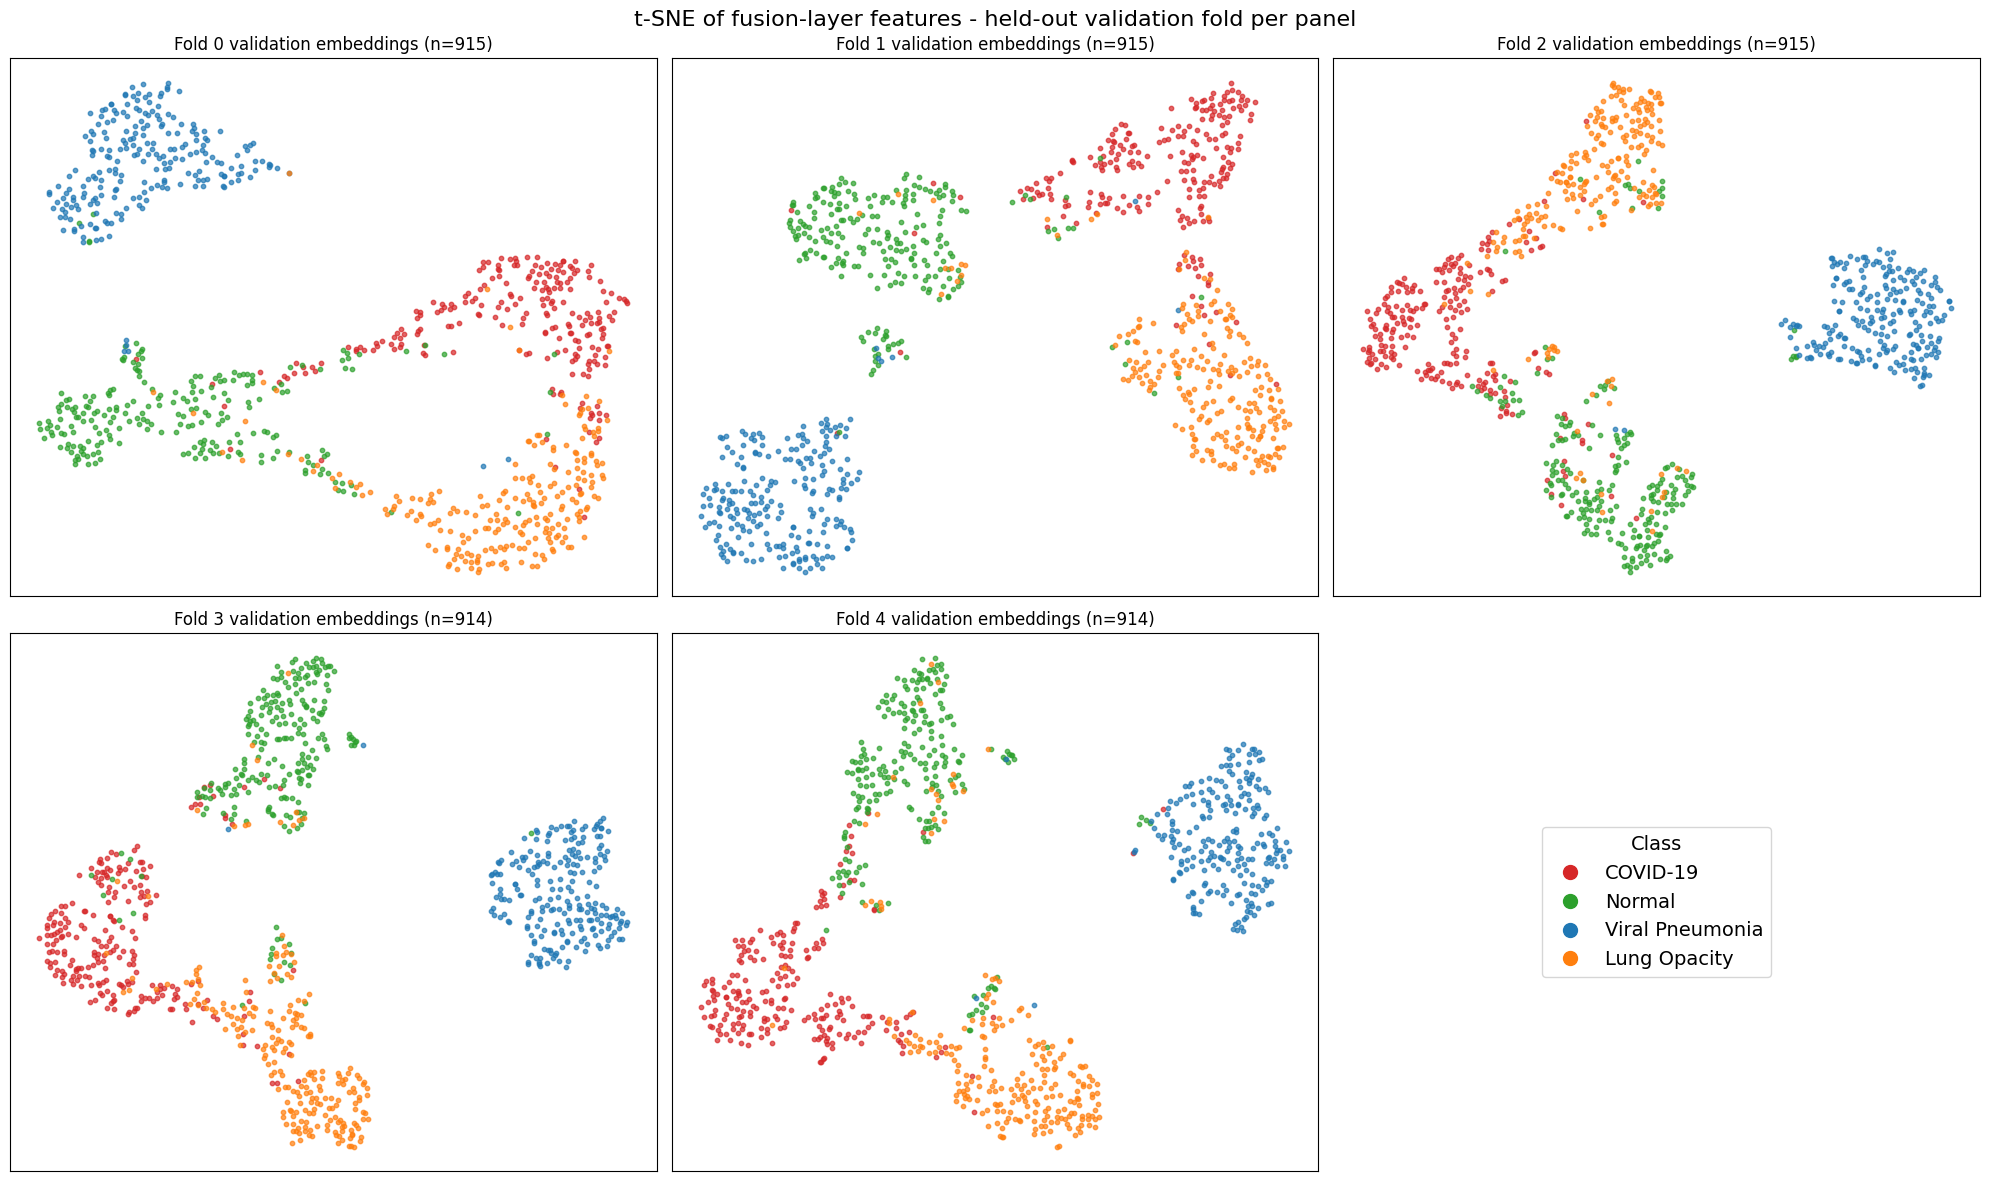

In [55]:
from sklearn.manifold import TSNE
from matplotlib.lines import Line2D

TSNE_SEED = 42
class_colors = ["#d62728", "#2ca02c", "#1f77b4", "#ff7f0e"]   # COVID-19, Normal, Viral Pneumonia, Lung Opacity

def run_tsne(features):
    return TSNE(
        n_components=2,
        perplexity=30,
        init="pca",
        learning_rate="auto",
        random_state=TSNE_SEED
    ).fit_transform(features)

fold_ids = df["fold"].values

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.ravel()

for tsne_fold in range(5):
    fmask = fold_ids == tsne_fold
    coords = run_tsne(oof_feats[fmask])

    for class_id in range(4):
        sel = oof_labels[fmask] == class_id
        axes[tsne_fold].scatter(coords[sel, 0], coords[sel, 1], s=10, alpha=0.7, c=class_colors[class_id])
    axes[tsne_fold].set_title(f"Fold {tsne_fold} validation embeddings (n={fmask.sum()})")
    axes[tsne_fold].set_xticks([]); axes[tsne_fold].set_yticks([])

axes[5].axis("off")
axes[5].legend(
    handles=[
        Line2D([0], [0], marker="o", linestyle="", color=class_colors[i], label=class_names[i], markersize=10)
        for i in range(4)
    ],
    loc="center", fontsize=14, title="Class", title_fontsize=14
)

plt.suptitle("t-SNE of fusion-layer features - held-out validation fold per panel", fontsize=16)
plt.tight_layout()
plt.savefig("/kaggle/working/tsne_per_fold.png", dpi=300, bbox_inches="tight")
plt.show()

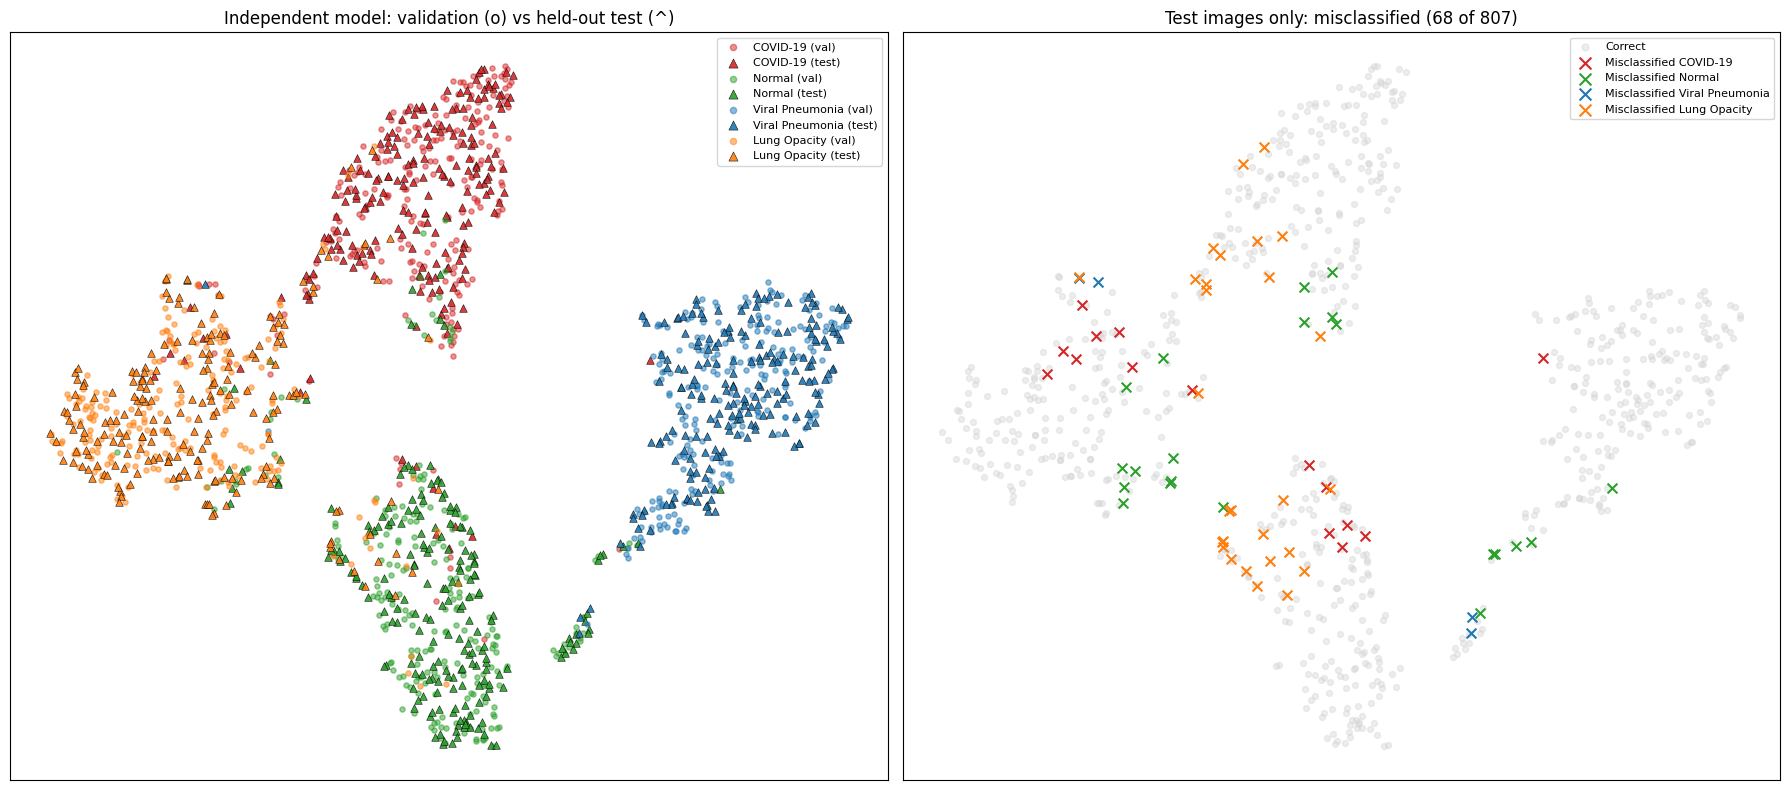

In [56]:
# Independent model: its validation images (o) and the untouched test images (^) in one embedding
ind_val_feats = extract_features(independent_model, val_cls_loader)
ind_test_feats = extract_features(independent_model, test_cls_loader)

ind_val_labels = val_cls_dataset.df["label"].values.astype(int)

joint_coords = run_tsne(np.concatenate([ind_val_feats, ind_test_feats], axis=0))
val_coords, test_coords = joint_coords[:len(ind_val_feats)], joint_coords[len(ind_val_feats):]
test_wrong = test_preds != test_labels

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for class_id in range(4):
    sv = ind_val_labels == class_id
    st = test_labels == class_id
    axes[0].scatter(val_coords[sv, 0], val_coords[sv, 1], s=14, alpha=0.5, marker="o",
                    c=class_colors[class_id], label=f"{class_names[class_id]} (val)")
    axes[0].scatter(test_coords[st, 0], test_coords[st, 1], s=30, alpha=0.9, marker="^",
                    c=class_colors[class_id], edgecolors="black", linewidths=0.4,
                    label=f"{class_names[class_id]} (test)")
axes[0].set_title("Independent model: validation (o) vs held-out test (^)")
axes[0].legend(markerscale=1.2, fontsize=8)

axes[1].scatter(test_coords[~test_wrong, 0], test_coords[~test_wrong, 1], s=18, alpha=0.4, c="lightgray", label="Correct")
for class_id in range(4):
    sel = test_wrong & (test_labels == class_id)
    axes[1].scatter(test_coords[sel, 0], test_coords[sel, 1], s=50, marker="x",
                    c=class_colors[class_id], label=f"Misclassified {class_names[class_id]}")
axes[1].set_title(f"Test images only: misclassified ({test_wrong.sum()} of {len(test_wrong)})")
axes[1].legend(markerscale=1.2, fontsize=8)

for a in axes:
    a.set_xticks([]); a.set_yticks([])

plt.tight_layout()
plt.savefig("/kaggle/working/tsne_independent_val_vs_test.png", dpi=300, bbox_inches="tight")
plt.show()

In [57]:
comparison_df = pd.DataFrame({
    "Metric": list(cv_metrics.keys()),
    "5-Fold OOF (development)": [v * 100 for v in cv_metrics.values()],
    "Independent model (test)": [v * 100 for v in final_metrics_test.values()],
})

print(f"Independent test samples: {len(test_labels)}\n")
print(comparison_df.round(2).to_string(index=False))

comparison_df.to_csv("/kaggle/working/cv_independent_comparison.csv", index=False)
print("\nSaved: /kaggle/working/cv_independent_comparison.csv")

Independent test samples: 807

   Metric  5-Fold OOF (development)  Independent model (test)
 Accuracy                     91.23                     91.57
Precision                     91.26                     91.54
   Recall                     91.23                     91.57
 F1-Score                     91.23                     91.54
  ROC-AUC                     98.39                     98.62

Saved: /kaggle/working/cv_independent_comparison.csv
